# __NB02: KSB and Course Matching__

*Author: Shilpa Kibe. Licensed under CC BY-NC 4.0.*

### __Overview__

In Notebook 1 we built synthetic datasets: 16 tables (.csvs) that mimic HRIS data, LMS data, and assessment data.

In this notebook, we use `courses.csv` and `ksbs.csv` to build the matching engine. We engineer features from course text and KSB text. This helps the model compare courses against KSBs.

**To do so we will:**
- take `course_title` + `description_raw` from `courses.csv` and build a text feature per course.
- take `ksb_text` from `ksbs.csv` and build a text feature per KSB.
- **vectorize both feature sets with TF-IDF**, so words turn into comparable numbers.
- **score every course-KSB pair by cosine similarity** between their vectors.

This tells us which courses best cover which skills, ranked by relevance.

**High level steps:**
- Step 2.1 — Gap Computation
- Step 2.2 — KSB Layer Auto-Tagging
- Step 2.3 — TF-IDF Matching Engine
- Step 2.4 — Embeddings Matching Engine
- Step 2.5 — Duplicate Detection
- Step 2.6 — Curation Layer
- Step 2.7 — Classifier Benchmark
- Step 2.8 — LDA Topic Modeling
- Step 2.9 —  Summary and Insights

In [1]:
# Step 2.0: Mount the Drive
import os
from google.colab import drive

if not os.path.ismount('/content/drive'):
    drive.mount('/content/drive')
    print("Drive mounted fresh.")
else:
    print("Drive already mounted — skipping remount, nothing deleted.")

Mounted at /content/drive
Drive mounted fresh.


### __Why We Mount Drive__

Colab gives us a fresh, empty computer every time we open it. It forgets everything once we close the session.

- Google Drive is our permanent storage. All 16 tables from NB01 live there.
- Mounting Drive connects this notebook to that storage, so we can read those tables.
- Without mounting, this notebook has no access to any file we built earlier.

### __Step 2.1: Compute Employee KSB Gaps__
- We score each employee's current skill level from their assessment answers.
- We compare that to what their role requires.
- We compute the size of the gap.
- This tells us exactly which skills each employee needs to close, and by how much.

### __Step 2.1.1: Load required Tables__

- We load the tables needed to compute each employee's skill gap.
- These come from NB01's synthetic data output.

In [2]:
# Step 2.1.1 Load assessment_responses + role_competency_requirements
# Load source tables for gap computation
import pandas as pd
import os

RAW_DIR = '/content/drive/MyDrive/Portfolio/LuminaLearningGroup/data/raw'

assessment_responses = pd.read_csv(os.path.join(RAW_DIR, "assessment_responses.csv"))
role_competency_requirements = pd.read_csv(os.path.join(RAW_DIR, "role_competency_requirements.csv"))
employees = pd.read_csv(os.path.join(RAW_DIR, "employees.csv"))
assessment_questions = pd.read_csv(os.path.join(RAW_DIR, "assessment_questions.csv"))
ksbs = pd.read_csv(os.path.join(RAW_DIR, "ksbs.csv"))

print("Step 2.1.1 executed — source tables loaded")
print(f"assessment_responses.csv: {len(assessment_responses)} rows")
print(f"role_competency_requirements.csv: {len(role_competency_requirements)} rows")
print(f"employees.csv: {len(employees)} rows")
print(f"assessment_questions.csv: {len(assessment_questions)} rows")
print(f"ksbs.csv: {len(ksbs)} rows")

Step 2.1.1 executed — source tables loaded
assessment_responses.csv: 1760 rows
role_competency_requirements.csv: 20 rows
employees.csv: 430 rows
assessment_questions.csv: 16 rows
ksbs.csv: 30 rows


### __Step 2.1.1 Notes/Insights__
- The scope of this demo is personalized learning paths for employees in two roles.
- This gap computation covers only the 55 employees in our 2 focus roles — Instructional Design Lead and Solution Architect.
- The other 2 roles exist in `employees.csv` but are out of scope, so their assessment data is not included.
- The assessment has two types of questions: proficiency and behavioural-barrier questions. Here we need only the proficiency-type responses.
- We keep only the current-year cycle, since that's what today's gap should reflect.
- We map each response to its competency, giving one actual_level per employee per competency.


### __Step 2.1.2: Score current-year proficiency responses__
- We keep only the current-year cycle, since that's what today's gap should reflect.
- We map each response to its competency, giving one actual_level per employee per competency.

In [3]:
# Step 2.1.2: Score current-year proficiency responses into actual_level per employee-competency

# --- Data prep step 1: keep only proficiency-type questions (drop the other question types) ---
# assessment_questions.csv — filter to proficiency-type rows only
proficiency_qs = assessment_questions[assessment_questions["question_type"] == "proficiency"]

# --- Data prep step 2: join responses to their linked competency ---
# assessment_responses.csv joined with the filtered proficiency questions
# pandas merge() works like Excel VLOOKUP
current_proficiency = assessment_responses.merge(
    proficiency_qs[["question_id", "linked_competency_id"]],
    on="question_id",
    how="inner"
)

# --- Data prep step 3: keep only the current-year assessment cycle ---
# assessment_responses.csv (post-join) — filter to current_year cycle only
current_proficiency = current_proficiency[current_proficiency["assessment_cycle"] == "current_year"]

# --- Data prep step 4: rename to final actual_level column names ---
# rename columns on the result from step 3, into actual_levels
actual_levels = current_proficiency[["employee_id", "linked_competency_id", "response_value"]].rename(
    columns={"linked_competency_id": "competency_id", "response_value": "actual_level"}
)

print("Step 2.1.2 executed — actual_level computed from assessment_responses.csv")
print(f"actual_levels: {len(actual_levels)} rows")
print(f"Unique employees in actual_levels: {actual_levels['employee_id'].nunique()}")
print(actual_levels.head())

Step 2.1.2 executed — actual_level computed from assessment_responses.csv
actual_levels: 550 rows
Unique employees in actual_levels: 55
  employee_id competency_id  actual_level
1     EMP0020        COMP01             2
3     EMP0020        COMP02             3
5     EMP0020        COMP03             4
7     EMP0020        COMP04             4
9     EMP0020        COMP05             1


### __Step 2.1.3: Employee KSB Gaps__

- We find each employee's role, then look up what proficiency level their role requires per competency.
- We subtract actual from required to get the gap size.
- We cascade each competency-level gap down to its 3 KSBs, since the assessment measures at competency level, not KSB level.
- This gives us the final `employee_ksb_gaps` table.

In [4]:
# Step 2.1.3: Join required_level, compute gap_size, cascade to KSBs

# --- Data prep step 1: attach each employee's role_id (employees.csv) ---
actual_with_role = actual_levels.merge(
    employees[["employee_id", "role_id"]],
    on="employee_id",
    how="left"
)

# --- Data prep step 2: look up required_level for that role+competency (role_competency_requirements.csv) ---
gaps_by_competency = actual_with_role.merge(
    role_competency_requirements[["role_id", "competency_id", "required_level"]],
    on=["role_id", "competency_id"],
    how="left"
)

# --- Data prep step 3: compute gap_size ---
gaps_by_competency["gap_size"] = gaps_by_competency["required_level"] - gaps_by_competency["actual_level"]

# --- Data prep step 4: cascade each competency-level gap to its 3 KSBs (ksbs.csv) ---
gaps_by_ksb = gaps_by_competency.merge(
    ksbs[["ksb_id", "competency_id"]],
    on="competency_id",
    how="left"
)

# --- Data prep step 5: assign surrogate gap_id, finalize columns ---
gaps_by_ksb = gaps_by_ksb.sort_values(["employee_id", "ksb_id"]).reset_index(drop=True)
gaps_by_ksb["gap_id"] = [f"GAP{i+1:06d}" for i in range(len(gaps_by_ksb))]

employee_ksb_gaps = gaps_by_ksb[["gap_id", "employee_id", "ksb_id", "required_level", "actual_level", "gap_size"]]

# --- Save ---
import os
PROCESSED_DIR = '/content/drive/MyDrive/Portfolio/LuminaLearningGroup/data/processed'
os.makedirs(PROCESSED_DIR, exist_ok=True)
employee_ksb_gaps.to_csv(os.path.join(PROCESSED_DIR, "employee_ksb_gaps.csv"), index=False)

print("Step 2.1.3 executed — employee_ksb_gaps.csv saved to data/processed")
print(f"employee_ksb_gaps: {len(employee_ksb_gaps)} rows")
print(f"Unique employees: {employee_ksb_gaps['employee_id'].nunique()}")
print(f"Unique KSBs: {employee_ksb_gaps['ksb_id'].nunique()}")
print(f"gap_size distribution:")
print(employee_ksb_gaps["gap_size"].describe())
print(employee_ksb_gaps.head())

Step 2.1.3 executed — employee_ksb_gaps.csv saved to data/processed
employee_ksb_gaps: 1650 rows
Unique employees: 55
Unique KSBs: 30
gap_size distribution:
count    1650.000000
mean        0.370909
std         0.834012
min        -2.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         3.000000
Name: gap_size, dtype: float64
      gap_id employee_id  ksb_id  required_level  actual_level  gap_size
0  GAP000001     EMP0020  KSB001               2             2         0
1  GAP000002     EMP0020  KSB002               2             2         0
2  GAP000003     EMP0020  KSB003               2             2         0
3  GAP000004     EMP0020  KSB004               3             3         0
4  GAP000005     EMP0020  KSB005               3             3         0


### __Step 2.1.3 Notes/Insights__

- Row count checks out exactly: 1,650 = 55 employees × 30 KSBs.
- Every focus-role employee now has a gap value for every KSB.

- `gap_size` is `required_level − actual_level`.
- A positive number means the employee is below where their role needs them — a real skill gap to close.
- Zero means they're exactly at the required level.
- A negative number means they exceed it.
- The median gap is 0 and most values cluster between 0 and 1 as expected.
- This is because we intentionally built in realistic-but-modest variance (ADR-0018), not extreme deficits.
- The max gap is 3 and the min is -2, so some employees exceed requirements on some competencies (negative gaps), and a few are 3 levels below the requirement on others.
- This gives the later matching engine genuine variation to work with, not a flat "everyone needs everything" scenario.

### __Step 2.2: KSB Layer Auto-Tagging__
- Step 2.1 told us which KSBs each employee is missing.
- It didn't tell us whether that KSB is knowledge or skill.
- We tag each course by KSB layer — knowledge or skill — using verb detection on its title and description.
- This layer tag helps the matching engine later distinguish "explains a concept" courses from "practice a skill" courses.

### __Step 2.2.1: Load Data__
- We load `courses.csv` and the `verb_ksb_layer_taxonomy.csv` we built in NB01.
- We turn the taxonomy into a lookup so we can check any word against it.
- We write a function that scans a course's title and description for these verbs and returns its KSB layer.

In [5]:
# Step 2.2.1: Load courses.csv and verb_ksb_layer_taxonomy.csv, build the tagging function

# --- Feature engineering step 1: load courses.csv and the verb taxonomy ---
courses = pd.read_csv(os.path.join(RAW_DIR, "courses.csv"))
verb_taxonomy = pd.read_csv(os.path.join(RAW_DIR, "verb_ksb_layer_taxonomy.csv"))

# --- Feature engineering step 2: turn the taxonomy into a verb -> ksb_layer lookup dict ---
verb_to_layer = dict(zip(verb_taxonomy["verb"], verb_taxonomy["ksb_layer"]))

# --- Feature engineering step 3: function to tag a course as knowledge or skill ---
def detect_ksb_layer(title, description):
    text = f"{title} {description}".lower()
    found_layers = [layer for verb, layer in verb_to_layer.items() if verb in text]

    if "skill" in found_layers:
        return "skill"
    elif "knowledge" in found_layers:
        return "knowledge"
    else:
        return "knowledge"  # fallback default — no course left untagged

print("Step 2.2.1 executed — courses.csv and verb_ksb_layer_taxonomy.csv loaded")
print(f"courses.csv: {len(courses)} rows")
print(f"verb_ksb_layer_taxonomy.csv: {len(verb_taxonomy)} verbs")

Step 2.2.1 executed — courses.csv and verb_ksb_layer_taxonomy.csv loaded
courses.csv: 154 rows
verb_ksb_layer_taxonomy.csv: 36 verbs


### __Self Learning Notes__
- Step 2.2.1 only loaded the data and defined the tagging function.
- it hasn't been run against any course yet.
- hence courses.csv's ksb_layer column is still empty (it's been NULL since NB01).
- We will apply this in step 2.2.2.

### __Step 2.2.2: Tag Courses__
- We apply the tagging function to every course. We populate `ksb_layer` for all 154 rows.
- We save the updated `courses.csv` back to `data/raw`, overwriting the version with the empty column.

In [6]:
# Step 2.2.2: Apply detect_ksb_layer to every course, save updated courses.csv

# --- Feature engineering step 4: apply the tagging function to every course ---
courses["ksb_layer"] = courses.apply(
    lambda row: detect_ksb_layer(row["course_title"], row["description_raw"]),
    axis=1
)

# --- Save: overwrite courses.csv in data/raw with ksb_layer now populated ---
courses.to_csv(os.path.join(RAW_DIR, "courses.csv"), index=False)

print("Step 2.2.2 executed — courses.csv updated with ksb_layer, saved to data/raw")
print(f"courses.csv: {len(courses)} rows")
print(courses["ksb_layer"].value_counts())
print(courses[["course_id", "course_title", "ksb_layer"]].head())

Step 2.2.2 executed — courses.csv updated with ksb_layer, saved to data/raw
courses.csv: 154 rows
ksb_layer
skill        117
knowledge     37
Name: count, dtype: int64
  course_id                                       course_title ksb_layer
0    CRS001              Mastering AI-Augmented Content Design     skill
1    CRS002         AI-Augmented Content Design: Core Concepts     skill
2    CRS003  Applying AI-Augmented Content Design to Real P...     skill
3    CRS004        Introduction to AI-Augmented Content Design     skill
4    CRS005            AI-Augmented Content Design in Practice     skill


### __Step 2.2.2 Notes/Insights__

- We now have `ksb_layer` for all 154 courses. 117 courses tag as `skill`. 37 courses tag as `knowledge`.
- This is a 76% skill / 24% knowledge split.
- Our verb taxonomy has a similar split: 26 skill verbs and 10 knowledge verbs (72% / 28%).
- The two splits are close. This is a good sanity check. It tells us the tagging function behaves the way the taxonomy predicts.
- Skill-heavy content makes sense here. Most course titles use applied language ("Mastering," "Applying," "in Practice"). These map to Bloom's higher-order verbs (Apply, Analyze, Evaluate, Create), which our taxonomy tags as `skill`.
- `courses.csv` in `data/raw` now has `ksb_layer` populated.

### __Step 2.3: TF-IDF Matching Engine__
- In 2.2 we tagged each course as `knowledge` or `skill`. That told us the *type* of each course.
- Now we go further: We match each course to the *specific* KSBs it covers.
- We score every course-KSB pair by text similarity.
- This tells us which courses are strong matches for which KSBs, not just which broad type they belong to.

### __Step 2.3.1:Build KSB and course text features__
- We build one text feature per course. We combine `course_title` and `description_raw`.
- We build one text feature per KSB. We use `ksb_text`.
- These text features are the raw input to TF-IDF in the next substep.

In [7]:
# Step 2.3.1: Build text features for courses and KSBs

import pandas as pd
import os

RAW_DIR = '/content/drive/MyDrive/Portfolio/LuminaLearningGroup/data/raw'

# --- Load source tables ---
courses = pd.read_csv(os.path.join(RAW_DIR, "courses.csv"))
ksbs = pd.read_csv(os.path.join(RAW_DIR, "ksbs.csv"))

# --- Feature engineering step 1: build one text feature per course ---
# course_title + description_raw, combined into a single string
courses["course_text_feature"] = (
    courses["course_title"].fillna("") + ". " + courses["description_raw"].fillna("")
)

# --- Feature engineering step 2: build one text feature per KSB ---
# ksb_text alone, since that's the only descriptive text ksbs.csv has
ksbs["ksb_text_feature"] = ksbs["ksb_text"].fillna("")

print("Step 2.3.1 executed — text features built for courses.csv and ksbs.csv")
print(f"courses.csv: {len(courses)} rows")
print(f"ksbs.csv: {len(ksbs)} rows")
print()
print(courses[["course_id", "course_text_feature"]].head(2))
print()
print(ksbs[["ksb_id", "ksb_text_feature"]].head(2))

Step 2.3.1 executed — text features built for courses.csv and ksbs.csv
courses.csv: 154 rows
ksbs.csv: 30 rows

  course_id                                course_text_feature
0    CRS001  Mastering AI-Augmented Content Design. Covers ...
1    CRS002  AI-Augmented Content Design: Core Concepts. Th...

   ksb_id                                   ksb_text_feature
0  KSB001  Understands capabilities/limitations of GenAI ...
1  KSB002  Can prompt-engineer GenAI tools to produce fir...


### __Step 2.3.2: Vectorize with TF-IDF__
- We turn the text features into numbers.
- We fit one TF-IDF vectorizer on courses and KSBs together, so both use the same vocabulary.
- We transform courses and KSBs separately, using that shared vocabulary.

In [8]:
# Step 2.3.2: Vectorize course and KSB text features with TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer

# --- Feature engineering step 3: fit TF-IDF on the combined vocabulary ---
# We fit on courses + ksbs together so both share the same word-to-column mapping.
# Without this, "prompt" in a course and "prompt" in a KSB could land in different columns.
combined_text = pd.concat([
    courses["course_text_feature"],
    ksbs["ksb_text_feature"]
], ignore_index=True)

vectorizer = TfidfVectorizer(stop_words="english")
vectorizer.fit(combined_text)

# --- Feature engineering step 4: transform courses and KSBs separately ---
# Same vocabulary, so the resulting vectors are directly comparable.
course_vectors = vectorizer.transform(courses["course_text_feature"])
ksb_vectors = vectorizer.transform(ksbs["ksb_text_feature"])

print("Step 2.3.2 executed — TF-IDF vectors built from courses.csv and ksbs.csv")
print(f"Vocabulary size: {len(vectorizer.get_feature_names_out())}")
print(f"course_vectors shape: {course_vectors.shape}")
print(f"ksb_vectors shape: {ksb_vectors.shape}")
print()
print("Sample vocabulary words:", list(vectorizer.get_feature_names_out()[:10]))

Step 2.3.2 executed — TF-IDF vectors built from courses.csv and ksbs.csv
Vocabulary size: 521
course_vectors shape: (154, 521)
ksb_vectors shape: (30, 521)

Sample vocabulary words: ['400', '69', 'abstract', 'academic', 'accepting', 'access', 'accuracy', 'achieving', 'adaptive', 'addie']


### __Step 2.3.3: Compute cosine similarity__
- We compare every course to every KSB. We use cosine similarity on their TF-IDF vectors.
- We get one score per course-KSB pair — 154 × 30 = 4620 pairs.
- We reshape this into a long table: one row per pair, so it's ready to save like our other derived tables.

In [9]:
# Step 2.3.3: Compute cosine similarity, build long-format course-KSB score table

from sklearn.metrics.pairwise import cosine_similarity

# --- Feature engineering step 5: compute cosine similarity ---
# similarity_matrix[i][j] = how similar course i is to ksb j
similarity_matrix = cosine_similarity(course_vectors, ksb_vectors)

print("Step 2.3.3a — similarity matrix computed")
print(f"similarity_matrix shape: {similarity_matrix.shape}")
print()

# --- Feature engineering step 6: reshape into long format (one row per pair) ---
mapping_rows = []
for i, course_row in courses.iterrows():
    for j, ksb_row in ksbs.iterrows():
        mapping_rows.append({
            "course_id": course_row["course_id"],
            "ksb_id": ksb_row["ksb_id"],
            "match_score": similarity_matrix[i][j]
        })

course_ksb_mapping = pd.DataFrame(mapping_rows)

print("Step 2.3.3b executed — long-format course-KSB score table built")
print(f"course_ksb_mapping: {len(course_ksb_mapping)} rows")
print()
print(course_ksb_mapping.sort_values("match_score", ascending=False).head(5))

Step 2.3.3a — similarity matrix computed
similarity_matrix shape: (154, 30)

Step 2.3.3b executed — long-format course-KSB score table built
course_ksb_mapping: 4620 rows

     course_id  ksb_id  match_score
2539    CRS085  KSB020     0.838384
3628    CRS121  KSB029     0.836101
2569    CRS086  KSB020     0.812120
3658    CRS122  KSB029     0.811973
3718    CRS124  KSB029     0.809081


### __Step 2.3.4: Update and save course_ksb_mapping__
- We add the remaining columns to `course_ksb_mapping`: a surrogate ID, the match method, a keyword-based explanation, and three metadata flags.
- We flag the top-scoring match(es) per KSB as recommended.
- We save the finished table to `data/processed`.

In [10]:
# Step 2.3.4: Finalize columns, add match_explanation, save course_ksb_mapping.csv

PROCESSED_DIR = '/content/drive/MyDrive/Portfolio/LuminaLearningGroup/data/processed'

# --- Feature engineering step 7: surrogate PK and fixed metadata ---
course_ksb_mapping["mapping_id"] = ["MAP" + str(i+1).zfill(5) for i in range(len(course_ksb_mapping))]
course_ksb_mapping["match_method"] = "tfidf"          # production method (ADR-0023)
course_ksb_mapping["is_production"] = True            # tfidf is the active production method
course_ksb_mapping["curation_status"] = "algo_suggested"  # NB02's initial value for every row (ADR-0036)

# --- Feature engineering step 8: match_explanation — top shared keywords per pair ---
feature_names = vectorizer.get_feature_names_out()

def top_shared_keywords(course_idx, ksb_idx, top_n=3):
    # Element-wise product of the two TF-IDF vectors highlights words that matter to BOTH.
    course_vec = course_vectors[course_idx].toarray().flatten()
    ksb_vec = ksb_vectors[ksb_idx].toarray().flatten()
    overlap = course_vec * ksb_vec
    top_indices = overlap.argsort()[::-1][:top_n]
    keywords = [feature_names[i] for i in top_indices if overlap[i] > 0]
    return ", ".join(keywords) if keywords else "no shared keywords"

course_ksb_mapping["match_explanation"] = course_ksb_mapping.apply(
    lambda row: top_shared_keywords(
        courses.index[courses["course_id"] == row["course_id"]][0],
        ksbs.index[ksbs["ksb_id"] == row["ksb_id"]][0]
    ),
    axis=1
)

# --- Feature engineering step 9: is_recommended — top-scoring match(es) per KSB (ADR-0036) ---
course_ksb_mapping["is_recommended"] = False
top_match_idx = course_ksb_mapping.groupby("ksb_id")["match_score"].idxmax()
course_ksb_mapping.loc[top_match_idx, "is_recommended"] = True

# --- Reorder columns to match the schema ---
course_ksb_mapping = course_ksb_mapping[[
    "mapping_id", "course_id", "ksb_id", "match_score", "match_method",
    "match_explanation", "is_production", "is_recommended", "curation_status"
]]

# --- Save ---
course_ksb_mapping.to_csv(os.path.join(PROCESSED_DIR, "course_ksb_mapping.csv"), index=False)

print("Step 2.3.4 executed — course_ksb_mapping.csv saved to data/processed")
print(f"course_ksb_mapping: {len(course_ksb_mapping)} rows")
print(f"is_recommended True: {course_ksb_mapping['is_recommended'].sum()} rows")
print()
print(course_ksb_mapping[course_ksb_mapping["is_recommended"]].sort_values("match_score", ascending=False).head(5))

# for each of the 30 KSBs, it finds the single row with the highest match_score across all 154 courses, and flags only that row.
# So we see only True rows whch are in this case 30--> one per ksb.

Step 2.3.4 executed — course_ksb_mapping.csv saved to data/processed
course_ksb_mapping: 4620 rows
is_recommended True: 30 rows

     mapping_id course_id  ksb_id  match_score match_method  \
2539   MAP02540    CRS085  KSB020     0.838384        tfidf   
3628   MAP03629    CRS121  KSB029     0.836101        tfidf   
2176   MAP02177    CRS073  KSB017     0.790514        tfidf   
1057   MAP01058    CRS036  KSB008     0.783025        tfidf   
1420   MAP01421    CRS048  KSB011     0.763590        tfidf   

                 match_explanation  is_production  is_recommended  \
2539            end, tool, operate           True            True   
3628      qa, generated, checklist           True            True   
2176           client, vague, asks           True            True   
1057  tagging, embedding, classify           True            True   
1420       mapping, profile, logic           True            True   

     curation_status  
2539  algo_suggested  
3628  algo_suggested  
2176  al

### __Step 2.3.4 Notes/Insights__

- `course_ksb_mapping.csv` is saved to `data/processed`, 4620 rows (154 courses × 30 KSBs).
- 30 rows are flagged `is_recommended = True` — one top match per KSB, as designed.
- `match_explanation` shows the words driving each score. For `CRS085`/`KSB020`, the shared words are "end, tool, operate" — this traces directly back to both texts using nearly the same phrase ("operate... end-to-end in a real workflow"). This confirms the score isn't a coincidence.
- `match_method = tfidf` and `is_production = True` on every row. This is our only matching method so far. Step 2.4 will add an `embedding` method for comparison, per ADR-0035.
- `curation_status = algo_suggested` on every row. This is the starting point. A human (L&D) review will move approved/modified rows forward later, per ADR-0036.
- This closes Step 2.3. `course_ksb_mapping.csv` is now the core output of the TF-IDF matching engine.

### __Step 2.4: Embedding Matching Engine (MiniLM)__
- In 2.3 we matched courses to KSBs using TF-IDF — word overlap.
- Now we try a second method: embeddings. Embeddings capture meaning, not just shared words.
- Two sentences can score high even with zero words in common, if they mean the same thing.
- We compare both methods side by side.
- This shows whether the extra complexity of embeddings actually buys us better matches, or whether TF-IDF was good enough.
- TF-IDF stays our production method either way (ADR-0035)
- This comparison shows whether embeddings add value.

### __Step 2.4.1: MiniLM embeddings for courses and KSBs__
- We load a pretrained sentence-embedding model (MiniLM).
- We encode each course's text feature into an embedding vector.
- We encode each KSB's text feature into an embedding vector.
- These reuse the same `course_text_feature` and `ksb_text_feature` columns built in 2.3.1. We dont need new text prep.

In [11]:
# Step 2.4.1: Load MiniLM, encode course and KSB text features as embeddings

try:
    from sentence_transformers import SentenceTransformer
except ImportError:
    import subprocess
    subprocess.run(["pip", "install", "-q", "--break-system-packages", "sentence-transformers"], check=True)
    from sentence_transformers import SentenceTransformer

# --- Feature engineering step 1: load pretrained model ---
# all-MiniLM-L6-v2: small, fast, widely-used sentence-embedding model (ADR-0035)
embed_model = SentenceTransformer("all-MiniLM-L6-v2")

# --- Feature engineering step 2: encode courses and ksbs (reusing 2.3.1's text features) ---
course_embeddings = embed_model.encode(courses["course_text_feature"].tolist(), show_progress_bar=False)
ksb_embeddings = embed_model.encode(ksbs["ksb_text_feature"].tolist(), show_progress_bar=False)

print("Step 2.4.1 executed — embeddings built from courses.csv and ksbs.csv")
print(f"course_embeddings shape: {course_embeddings.shape}")
print(f"ksb_embeddings shape: {ksb_embeddings.shape}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Step 2.4.1 executed — embeddings built from courses.csv and ksbs.csv
course_embeddings shape: (154, 384)
ksb_embeddings shape: (30, 384)


### __Step 2.4.2: Cosine similarity__
- We compare every course to every KSB, same as 2.3.3, but using embeddings instead of TF-IDF vectors.
- We get one similarity score per course-KSB pair.
- We reshape into a long table, one row per pair.

In [12]:
# Step 2.4.2: Compute embedding cosine similarity, build long-format score table

# --- Feature engineering step 3: compute cosine similarity on embeddings ---
embedding_similarity_matrix = cosine_similarity(course_embeddings, ksb_embeddings)

print("Step 2.4.2a — embedding similarity matrix computed")
print(f"embedding_similarity_matrix shape: {embedding_similarity_matrix.shape}")
print()

# --- Feature engineering step 4: reshape into long format (one row per pair) ---
embedding_mapping_rows = []
for i, course_row in courses.iterrows():
    for j, ksb_row in ksbs.iterrows():
        embedding_mapping_rows.append({
            "course_id": course_row["course_id"],
            "ksb_id": ksb_row["ksb_id"],
            "match_score": embedding_similarity_matrix[i][j]
        })

embedding_mapping = pd.DataFrame(embedding_mapping_rows)

print("Step 2.4.2b executed — long-format embedding score table built")
print(f"embedding_mapping: {len(embedding_mapping)} rows")
print()
print(embedding_mapping.sort_values("match_score", ascending=False).head(5))

Step 2.4.2a — embedding similarity matrix computed
embedding_similarity_matrix shape: (154, 30)

Step 2.4.2b executed — long-format embedding score table built
embedding_mapping: 4620 rows

     course_id  ksb_id  match_score
1057    CRS036  KSB008     0.845253
3718    CRS124  KSB029     0.831084
90      CRS004  KSB001     0.817085
3628    CRS121  KSB029     0.815938
0       CRS001  KSB001     0.807372


### __Step 2.4.2c: Compare TF-IDF vs MiniLM Embedding top-match agreement__
- We check how often **TF-IDF** and **MiniLM Embeddings** agree on the top course for each KSB.
- We compare the top-scoring course per KSB from each method.
- This tells us how much the two methods actually disagree, not just what we eyeballed in the top 5.

In [13]:
# Step 2.4.2c: Compare TF-IDF vs embedding top-match agreement, per KSB

# --- Top TF-IDF course per KSB (from 2.3.3's similarity_matrix) ---
tfidf_top = pd.DataFrame({
    "ksb_id": ksbs["ksb_id"],
    "tfidf_top_course": [courses.iloc[similarity_matrix[:, j].argmax()]["course_id"] for j in range(len(ksbs))],
    "tfidf_top_score": [similarity_matrix[:, j].max() for j in range(len(ksbs))]
})

# --- Top embedding course per KSB (from 2.4.2's embedding_similarity_matrix) ---
embedding_top = pd.DataFrame({
    "ksb_id": ksbs["ksb_id"],
    "embedding_top_course": [courses.iloc[embedding_similarity_matrix[:, j].argmax()]["course_id"] for j in range(len(ksbs))],
    "embedding_top_score": [embedding_similarity_matrix[:, j].max() for j in range(len(ksbs))]
})

comparison = tfidf_top.merge(embedding_top, on="ksb_id")
comparison["methods_agree"] = comparison["tfidf_top_course"] == comparison["embedding_top_course"]

agree_count = comparison["methods_agree"].sum()
print("Step 2.4.2c executed — TF-IDF vs embedding top-match agreement checked")
print(f"KSBs where both methods pick the same top course: {agree_count} / {len(comparison)}")
print(f"Average TF-IDF top score: {comparison['tfidf_top_score'].mean():.3f}")
print(f"Average embedding top score: {comparison['embedding_top_score'].mean():.3f}")
print()
display(comparison)

# --- Feature engineering step (addition): score_gap — how confidently the two methods agree/disagree ---
comparison["score_gap"] = (comparison["tfidf_top_score"] - comparison["embedding_top_score"]).abs()

print(f"Average score gap: {comparison['score_gap'].mean():.3f}")
print(f"Largest score gap: {comparison['score_gap'].max():.3f} (KSB: {comparison.loc[comparison['score_gap'].idxmax(), 'ksb_id']})")
print()
display(comparison.sort_values("score_gap", ascending=False))

Step 2.4.2c executed — TF-IDF vs embedding top-match agreement checked
KSBs where both methods pick the same top course: 17 / 30
Average TF-IDF top score: 0.669
Average embedding top score: 0.690



,ksb_id,tfidf_top_course,tfidf_top_score,embedding_top_course,embedding_top_score,methods_agree
0,KSB001,CRS001,0.649768,CRS004,0.817085,False
1,KSB002,CRS008,0.759813,CRS008,0.735110,True
2,KSB003,CRS010,0.542246,CRS011,0.797495,False
3,KSB004,CRS014,0.744515,CRS014,0.688401,True
4,KSB005,CRS020,0.754176,CRS019,0.777013,False
5,KSB006,CRS026,0.604388,CRS028,0.509733,False
6,KSB007,CRS032,0.741477,CRS032,0.720348,True
7,KSB008,CRS036,0.783025,CRS036,0.845253,True
8,KSB009,CRS040,0.701984,CRS040,0.789364,True
9,KSB010,CRS042,0.607159,CRS041,0.750896,False


Average score gap: 0.090
Largest score gap: 0.255 (KSB: KSB003)



,ksb_id,tfidf_top_course,tfidf_top_score,embedding_top_course,embedding_top_score,methods_agree,score_gap
2,KSB003,CRS010,0.542246,CRS011,0.797495,False,0.255248
20,KSB021,CRS089,0.598718,CRS089,0.387102,True,0.211616
18,KSB019,CRS083,0.579103,CRS083,0.759359,True,0.180257
12,KSB013,CRS055,0.541919,CRS055,0.720393,True,0.178473
29,KSB030,CRS129,0.545812,CRS129,0.715229,True,0.169417
0,KSB001,CRS001,0.649768,CRS004,0.817085,False,0.167317
9,KSB010,CRS042,0.607159,CRS041,0.750896,False,0.143737
19,KSB020,CRS085,0.838384,CRS086,0.697754,False,0.140630
16,KSB017,CRS073,0.790514,CRS073,0.661449,True,0.129065
24,KSB025,CRS106,0.652219,CRS106,0.763834,True,0.111616


### __Step 2.4.2c Notes/Insights__

- TF-IDF and embeddings agree on the top course for 17 of 30 KSBs (57%). They disagree for 13.
- Agreement isn't all equally strong.
  - Some agreements have a tiny score gap--> **KSB016 (gap 0.012)**, **KSB024 (gap 0.013)**, **KSB028 (gap 0.019)**. Both methods are confident and aligned here.
- Other "agreements" have a large gap--> **KSB021 (gap 0.212, scores 0.599 vs 0.387)**.
  - Both methods pick the same course, but one is far more confident than the other.
  - This is a weak agreement, not a strong one.
- Disagreements also vary. **KSB029 has the smallest gap of any disagreement (0.005, scores 0.836 vs 0.831)** — both methods are highly confident, just in two different courses.
  - This is a genuine, close contest between two strong candidates, not a random mismatch.
- This tells us raw score alone isn't enough to trust a match.
  - Agreement between two independent methods is a stronger signal than either method's score in isolation.

**TF-IDF wins on explainability:**
- for every match, we can name the exact shared words (match_explanation in 2.3.4).
- Embeddings can't do that (2.4.3's explanation is a generic note, not specific words).
- The 57% true (where both models are aligned) are our safe choices.
- The remaining 13 have two valid candidates (see 2.7.6), so a person picks the better one.

### __Step 2.4.3: Combine Embedding with TF-IDF Rows__

- We add the remaining columns to the embedding table: a surrogate ID, the match method, a plain-language explanation, and the metadata flags.
- We flag the top-scoring match(es) per KSB as recommended, same rule as 2.3.4.
- We combine this with the TF-IDF table and save both together to `course_ksb_mapping.csv`, overwriting the TF-IDF-only version.

In [14]:
# Step 2.4.3: Finalize embedding columns, combine with TF-IDF rows, save course_ksb_mapping.csv

# --- Feature engineering step 5: surrogate PK and fixed metadata ---
start_id = len(course_ksb_mapping) + 1
embedding_mapping["mapping_id"] = ["MAP" + str(start_id + i).zfill(5) for i in range(len(embedding_mapping))]
embedding_mapping["match_method"] = "embedding"      # comparison method (ADR-0035)
embedding_mapping["is_production"] = False           # tfidf remains production, not this
embedding_mapping["curation_status"] = "algo_suggested"

# --- Feature engineering step 6: match_explanation — plain note, not a keyword list ---
# Embeddings are dense, learned numbers — no single dimension maps to a word,
# so we can't point at "shared words" the way TF-IDF does (see Step 2.4 note).
embedding_mapping["match_explanation"] = "semantic similarity (embedding-based, not word-based)"

# --- Feature engineering step 7: is_recommended — top-scoring match(es) per KSB, same rule as 2.3.4 ---
embedding_mapping["is_recommended"] = False
top_embedding_idx = embedding_mapping.groupby("ksb_id")["match_score"].idxmax()
embedding_mapping.loc[top_embedding_idx, "is_recommended"] = True

# --- Reorder columns to match the schema ---
embedding_mapping = embedding_mapping[[
    "mapping_id", "course_id", "ksb_id", "match_score", "match_method",
    "match_explanation", "is_production", "is_recommended", "curation_status"
]]

# --- Combine with the TF-IDF rows from Step 2.3.4 and save ---
course_ksb_mapping = pd.concat([course_ksb_mapping, embedding_mapping], ignore_index=True)
course_ksb_mapping.to_csv(os.path.join(PROCESSED_DIR, "course_ksb_mapping.csv"), index=False)

print("Step 2.4.3 executed — course_ksb_mapping.csv updated with embedding rows, saved to data/processed")
print(f"course_ksb_mapping: {len(course_ksb_mapping)} rows total")
print(course_ksb_mapping["match_method"].value_counts())
print()
display(course_ksb_mapping[course_ksb_mapping["match_method"] == "embedding"].head(3))

Step 2.4.3 executed — course_ksb_mapping.csv updated with embedding rows, saved to data/processed
course_ksb_mapping: 9240 rows total
match_method
tfidf        4620
embedding    4620
Name: count, dtype: int64



,mapping_id,course_id,ksb_id,match_score,match_method,match_explanation,is_production,is_recommended,curation_status
4620,MAP04621,CRS001,KSB001,0.807372,embedding,"semantic similarity (embedding-based, not word...",False,False,algo_suggested
4621,MAP04622,CRS001,KSB002,0.668289,embedding,"semantic similarity (embedding-based, not word...",False,False,algo_suggested
4622,MAP04623,CRS001,KSB003,0.583204,embedding,"semantic similarity (embedding-based, not word...",False,False,algo_suggested


### __Step 2.4.3 Notes/Insights__

- `course_ksb_mapping.csv` now holds 9240 rows: 4620 `tfidf` (production) + 4620 `embedding` (comparison), one row per method per course-KSB pair.
- `is_production = True` only on `tfidf` rows. This is what the Path Engine will actually read (NB03).
- `is_recommended` is flagged independently per method — 30 `True` rows for `tfidf`, 30 for `embedding` — since each method has its own opinion on the best course per KSB (2.4.2c showed they agree 57% of the time).
- `match_explanation` differs by method: TF-IDF gives real shared keywords; embedding gives a plain semantic-similarity note, since embeddings aren't word-interpretable.
- `curation_status = algo_suggested` on every row, both methods. This is the starting point for the human review layer (ADR-0036), still to come.
- This closes Step 2.4. We now have two independently-scored matching methods side by side, with data-backed agreement analysis (2.4.2c) to justify keeping TF-IDF as production while surfacing embeddings' value as a comparison.

### __Step 2.5: Duplicate Detection__
- In 2.4 we compared courses to KSBs. Now we compare courses to *other courses*.
- We reuse the same embedding vectors from 2.4.1 — no new encoding needed.
- This finds courses that are near-duplicates of each other, which matters because our catalog was deliberately built with some redundancy (min 3, mean 4.33, max 5 courses per KSB, per ADR-0034).

### __Step 2.5.1: Closest Match using MiniLM__

- We compare every course to every other course, using the same MiniLM embeddings from 2.4.1.
- For each course, we find its single most similar other course.
- We look at the spread of these top similarity scores before picking a cutoff.
    - This way we ensure the cutoff is grounded in what the data actually looks like, not a guess.

In [15]:
# Step 2.5.1: Course-to-course similarity, find each course's closest match

# --- Feature engineering step 1: course-to-course cosine similarity ---
# Reuses course_embeddings from 2.4.1 — same vectors, compared against themselves this time.
course_to_course_similarity = cosine_similarity(course_embeddings, course_embeddings)

# --- Feature engineering step 2: for each course, find its closest OTHER course ---
# We set the diagonal to -1 so a course never matches itself.
import numpy as np
np.fill_diagonal(course_to_course_similarity, -1)

closest_course_idx = course_to_course_similarity.argmax(axis=1)
closest_course_score = course_to_course_similarity.max(axis=1)

duplicate_candidates = pd.DataFrame({
    "course_id": courses["course_id"],
    "closest_course_id": courses.iloc[closest_course_idx]["course_id"].values,
    "closest_score": closest_course_score
})

print("Step 2.5.1 executed — course-to-course similarity computed")
print(f"course_to_course_similarity shape: {course_to_course_similarity.shape}")
print()
print("Distribution of closest_score (each course's best match to another course):")
print(duplicate_candidates["closest_score"].describe())
print()
print(duplicate_candidates.sort_values("closest_score", ascending=False).head(10))

# Check which courses sit in the low-similarity tail
print("Check which courses sit in the low-similarity tail")
print(duplicate_candidates[duplicate_candidates["closest_score"] < 0.7])

Step 2.5.1 executed — course-to-course similarity computed
course_to_course_similarity shape: (154, 154)

Distribution of closest_score (each course's best match to another course):
count    154.000000
mean       0.902173
std        0.084807
min        0.411047
25%        0.885940
50%        0.922236
75%        0.941250
max        0.983309
Name: closest_score, dtype: float64

    course_id closest_course_id  closest_score
88     CRS089            CRS088       0.983309
87     CRS088            CRS089       0.983309
7      CRS008            CRS006       0.980529
5      CRS006            CRS008       0.980529
49     CRS050            CRS048       0.971788
47     CRS048            CRS050       0.971788
37     CRS038            CRS037       0.963842
36     CRS037            CRS038       0.963842
145    CRS146            CRS137       0.962972
136    CRS137            CRS146       0.962972
Check which courses sit in the low-similarity tail
    course_id closest_course_id  closest_score
142   

### __Step 2.5.1 Notes/Insights__
- mean 0.902, std 0.085: the catalog is topically narrow (all L&D/GenAI courses).
- Hence even unrelated courses land around 0.88–0.90.
- A flat "0.9" threshold would flag most of the catalog, this isn't meaningful.

**The real signal is at the top:** scores above 0.95 sit clearly apart from the general baseline (mean+std ≈ 0.987, but the top 5 pairs cluster tightly between 0.96–0.98, then drop off)

### __Step 2.5.1b: Histogram of closest score distribution__
- Plot a Histogram to see the distribution we just looked at as numbers.
- It will tell us why 0.95 is a meaningful cutoff (a small cluster of pairs stands apart from the bulk).

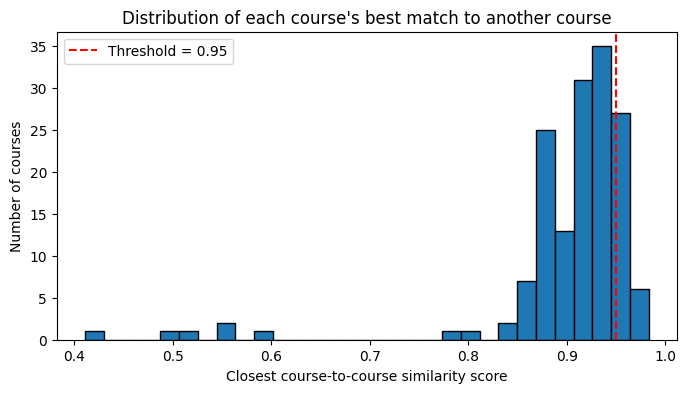

In [16]:
# Step 2.5.1b: Visualize the closest_score distribution to sanity-check the threshold

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.hist(duplicate_candidates["closest_score"], bins=30, edgecolor="black")
plt.axvline(0.95, color="red", linestyle="--", label="Threshold = 0.95")
plt.xlabel("Closest course-to-course similarity score")
plt.ylabel("Number of courses")
plt.title("Distribution of each course's best match to another course")
plt.legend()
plt.show()

### __Step 2.5.1b: Histogram Observations__
- The bulk of courses sit between 0.85–0.97.
- Means "topically similar but not duplicate" baseline we expected, since the whole catalog is L&D/GenAI content.

- A handful sit off to the left, around 0.42–0.6 (left tail).
- These are the orphan courses and the four real arXiv rows, (not orphans alone).
- They don't closely resemble anything else in the catalog.

- Our 0.95 threshold line sits right at the edge of the distribution's main mass.
- It catches only the courses in that rightmost tail — not the bulk.
- This  is the duplicate area.

### __Step 2.5.2: Apply Duplicate Threshold__
- We pick 0.95 as the duplicate threshold.
- This sits above the catalog's typical topical similarity (mean 0.902).
- This way, it only catches courses that are unusually close, not just "same general subject."
- We flag `likely_duplicate_of` only for courses above this threshold. We save the updated `courses.csv`.

In [17]:
# Step 2.5.2: Apply duplicate threshold, populate courses.likely_duplicate_of, save

DUPLICATE_THRESHOLD = 0.95

# --- Feature engineering step 3: flag likely duplicates above threshold ---
# NULL (None) for courses below the threshold — matches schema convention (NULL if no duplicate found)
courses["likely_duplicate_of"] = [
    duplicate_candidates.iloc[i]["closest_course_id"] if duplicate_candidates.iloc[i]["closest_score"] >= DUPLICATE_THRESHOLD else None
    for i in range(len(courses))
]

# --- Save: overwrite courses.csv in data/raw with likely_duplicate_of populated ---
courses.to_csv(os.path.join(RAW_DIR, "courses.csv"), index=False)

flagged_count = courses["likely_duplicate_of"].notna().sum()
print(f"Step 2.5.2 executed — courses.csv updated with likely_duplicate_of (threshold={DUPLICATE_THRESHOLD}), saved to data/raw")
print(f"Courses flagged as likely duplicates: {flagged_count} / {len(courses)}")
print()
display(courses[courses["likely_duplicate_of"].notna()][["course_id", "course_title", "likely_duplicate_of"]])

Step 2.5.2 executed — courses.csv updated with likely_duplicate_of (threshold=0.95), saved to data/raw
Courses flagged as likely duplicates: 27 / 154



,course_id,course_title,likely_duplicate_of
0,CRS001,Mastering AI-Augmented Content Design,CRS004
2,CRS003,Applying AI-Augmented Content Design to Real P...,CRS007
3,CRS004,Introduction to AI-Augmented Content Design,CRS001
4,CRS005,AI-Augmented Content Design in Practice,CRS004
5,CRS006,Advanced AI-Augmented Content Design Techniques,CRS008
6,CRS007,Applying AI-Augmented Content Design to Real P...,CRS003
7,CRS008,AI-Augmented Content Design in Practice,CRS006
25,CRS026,Mastering Data-Driven Learning Analytics,CRS027
26,CRS027,Advanced Data-Driven Learning Analytics Techni...,CRS026
33,CRS034,Advanced NLP-Based Content Curation Techniques,CRS036


### __Step 2.5.2 Notes/Insights__

- 27 of 154 courses flagged as likely duplicates.
- Most are clean pairs. Some form bigger clusters (e.g. CRS001, CRS004, CRS005).
- This is detection only. Choosing which course to retire would need usage and cost data this project does not have.

### __Step 2.5.3: How to Handle Triplets/Clusters__
- We build all course-pairs above the 0.95 threshold, not just each course's single closest match.
- We group courses into clusters using these pairs — if A is close to B, and B is close to C, all three belong to one cluster, even if A and C aren't each other's closest match.
- We add `duplicate_cluster_id` to `courses.csv` so every course in the same family shares one ID.

In [18]:
# Step 2.5.3: Build duplicate clusters using connected components (not just single nearest-neighbor)

import networkx as nx

# --- Feature engineering step 4: build a graph — edge if similarity >= threshold ---
# Note: course_to_course_similarity already has its diagonal set to -1 (Step 2.5.1),
# so no course can form an edge with itself.
graph = nx.Graph()
graph.add_nodes_from(courses["course_id"])

n_courses = len(courses)
for i in range(n_courses):
    for j in range(i + 1, n_courses):  # each pair checked once
        if course_to_course_similarity[i][j] >= DUPLICATE_THRESHOLD:
            graph.add_edge(courses.iloc[i]["course_id"], courses.iloc[j]["course_id"])

# --- Feature engineering step 5: connected components = duplicate clusters ---
# A cluster of size 1 (no edges) means "no duplicates" — gets no cluster ID.
clusters = [c for c in nx.connected_components(graph) if len(c) > 1]

course_to_cluster = {}
for cluster_num, course_ids in enumerate(clusters, start=1):
    cluster_id = f"DUPCLUST{str(cluster_num).zfill(3)}"
    for cid in course_ids:
        course_to_cluster[cid] = cluster_id

courses["duplicate_cluster_id"] = courses["course_id"].map(course_to_cluster)

# --- Save: overwrite courses.csv with duplicate_cluster_id added ---
courses.to_csv(os.path.join(RAW_DIR, "courses.csv"), index=False)

print("Step 2.5.3 executed — courses.csv updated with duplicate_cluster_id, saved to data/raw")
print(f"Duplicate clusters found: {len(clusters)}")
print(f"Courses in a cluster: {courses['duplicate_cluster_id'].notna().sum()} / {len(courses)}")
print()
display(courses[courses["duplicate_cluster_id"].notna()].sort_values("duplicate_cluster_id")[
    ["course_id", "course_title", "likely_duplicate_of", "duplicate_cluster_id"]
])

Step 2.5.3 executed — courses.csv updated with duplicate_cluster_id, saved to data/raw
Duplicate clusters found: 12
Courses in a cluster: 27 / 154



,course_id,course_title,likely_duplicate_of,duplicate_cluster_id
0,CRS001,Mastering AI-Augmented Content Design,CRS004,DUPCLUST001
2,CRS003,Applying AI-Augmented Content Design to Real P...,CRS007,DUPCLUST001
3,CRS004,Introduction to AI-Augmented Content Design,CRS001,DUPCLUST001
4,CRS005,AI-Augmented Content Design in Practice,CRS004,DUPCLUST001
6,CRS007,Applying AI-Augmented Content Design to Real P...,CRS003,DUPCLUST001
5,CRS006,Advanced AI-Augmented Content Design Techniques,CRS008,DUPCLUST002
7,CRS008,AI-Augmented Content Design in Practice,CRS006,DUPCLUST002
25,CRS026,Mastering Data-Driven Learning Analytics,CRS027,DUPCLUST003
26,CRS027,Advanced Data-Driven Learning Analytics Techni...,CRS026,DUPCLUST003
33,CRS034,Advanced NLP-Based Content Curation Techniques,CRS036,DUPCLUST004


### __Step 2.5.3 Notes/Insights__

- 12 duplicate clusters found, sizes 2 to 5.
- Largest: DUPCLUST001, 5 courses, all "AI-Augmented Content Design."
- Clustering caught courses pairwise matching missed (e.g. CRS003, CRS007 — each other's #1, both also link to CRS001/004/005, so all five sit in the same cluster DUPCLUST001. Nearest-neighbor alone would have missed that link).


### __Step 2.6: Curation__

- We now decide which matches a human should review.
- We use the agreement data from 2.4.2c.
- Strong, confident matches auto-approve.
- Weak or disagreeing matches go to review.

### __Step 2.6.1: Rule-based curation__

- We update `curation_status` for the 30 recommended TF-IDF matches.
- Rule: both methods agree AND scores are close (gap < 0.10) → auto-approved. Otherwise → needs review.
- This only touches production (TF-IDF) rows — those are what NB03 actually uses.

In [19]:
# Step 2.6.1: Rule-based curation — auto-approve confident matches, flag the rest for review

CONFIDENCE_GAP_THRESHOLD = 0.10

# --- Feature engineering step 1: build a lookup from comparison (2.4.2c) ---
comparison_lookup = comparison.set_index("ksb_id")[["methods_agree", "score_gap"]]

# --- Feature engineering step 2: apply the rule to production (tfidf) recommended rows ---
def decide_curation_status(row):
    if row["match_method"] != "tfidf" or not row["is_recommended"]:
        return row["curation_status"]  # unchanged — only touch tfidf + recommended rows
    agree = comparison_lookup.loc[row["ksb_id"], "methods_agree"]
    gap = comparison_lookup.loc[row["ksb_id"], "score_gap"]
    if agree and gap < CONFIDENCE_GAP_THRESHOLD:
        return "ld_approved"
    else:
        return "ld_reviewed"

course_ksb_mapping["curation_status"] = course_ksb_mapping.apply(decide_curation_status, axis=1)

print("Step 2.6.1 executed — curation_status updated for recommended tfidf rows")
print(course_ksb_mapping[
    (course_ksb_mapping["match_method"] == "tfidf") & (course_ksb_mapping["is_recommended"])
]["curation_status"].value_counts())

Step 2.6.1 executed — curation_status updated for recommended tfidf rows
curation_status
ld_reviewed    19
ld_approved    11
Name: count, dtype: int64


### __Step 2.6.1 Notes/Insights__

- 11 of 30 recommended matches auto-approved (confident, agreeing).
- 19 flagged for human review (weak confidence or disagreement).
  - Step 2.7.6 later confirms all 19 are correct matches. Review here means choosing between valid courses.
- This is our simulated review queue: the real system's judgment layer.

### __Step 2.6.2: Save updated table__

We save the updated `course_ksb_mapping.csv` with curation decisions applied.

In [20]:
# Step 2.6.2: Save course_ksb_mapping.csv with curation_status applied

course_ksb_mapping.to_csv(os.path.join(PROCESSED_DIR, "course_ksb_mapping.csv"), index=False)

print("Step 2.6.2 executed — course_ksb_mapping.csv saved to data/processed")
print(course_ksb_mapping["curation_status"].value_counts())

Step 2.6.2 executed — course_ksb_mapping.csv saved to data/processed
curation_status
algo_suggested    9210
ld_reviewed         19
ld_approved         11
Name: count, dtype: int64


### __Step 2.6.2 Notes/Insights__

- 9210 rows untouched (`algo_suggested`) — only recommended tfidf rows go through curation.
- 30 recommended rows now split: 11 approved, 19 for review.

### __Step 2.7: Classifier Benchmark__

- **Step 2.7 builds a supervised classifier:** given a course's text, predict which competency it belongs to.
- We'll benchmark it against TF-IDF's matching approach using the real target_competency_id labels NB01 now generates.
- This classifier's output won't be saved to course_ksb_mapping.
- It is comparison-only (ADR-0023). We use it to show whether a trained model beats keyword-overlap matching.

### __Step 2.7.1 — Load courses.csv and inspect the label__
- Before training anything, we need to know what we're working with.
- Does every course have a real **target_competency_id**, or do some (like the orphan/generic courses) have none?
- A classifier needs a label for every training row, so this tells us whether we need to drop some rows first.

In [21]:
# Step 2.7.1: Load courses.csv, inspect target_competency_id coverage

courses = pd.read_csv(os.path.join(RAW_DIR, "courses.csv"))

print("Step 2.7.1 executed — courses.csv loaded, target_competency_id inspected")
print(f"courses.csv: {len(courses)} rows")
print(f"Rows with a target_competency_id: {courses['target_competency_id'].notna().sum()}")
print(f"Rows with target_competency_id missing (NaN): {courses['target_competency_id'].isna().sum()}")
print()
print("target_competency_id distribution:")
print(courses["target_competency_id"].value_counts(dropna=False))

Step 2.7.1 executed — courses.csv loaded, target_competency_id inspected
courses.csv: 154 rows
Rows with a target_competency_id: 130
Rows with target_competency_id missing (NaN): 24

target_competency_id distribution:
target_competency_id
NaN       24
COMP10    15
COMP02    15
COMP06    14
COMP01    13
COMP05    13
COMP04    13
COMP03    12
COMP09    12
COMP08    12
COMP07    11
Name: count, dtype: int64


### __Step 2.7.1 Notes/Insights__

- 130 of 154 courses have a real label; 24 don't.
- 24 = 20 orphan/generic courses (ADR-0034) + 4 real-excerpt arXiv rows (CRS151–154).
- both groups exist outside the KSB taxonomy by design, so no label is correct, not a data gap.
- The 130 labeled rows split close to evenly across the 10 competencies (11–15 each).
- This is fine since a lopsided split would bias the classifier toward the bigger classes.

**We train and test only on these 130 rows; the 24 unlabeled rows are excluded from this benchmark entirely.**

### __Step 2.7.2 — Filter to labeled rows, build train/test split__
- A classifier needs to be judged on data it hasn't seen.
- We'll hold back a slice of the 130 labeled courses as a test set, train only on the rest.
- Then we will check how well it predicts the held-back slice's actual competency.

In [22]:
# Step 2.7.2: Filter to labeled courses, build train/test split

from sklearn.model_selection import train_test_split

# --- Step 1: keep only courses with a real label ---
labeled_courses = courses[courses["target_competency_id"].notna()].copy()

# --- Step 2: build the same text feature used for TF-IDF (title + description) ---
labeled_courses["course_text_feature"] = (
    labeled_courses["course_title"].fillna("") + ". " + labeled_courses["description_raw"].fillna("")
)

# --- Step 3: train/test split, stratified so each competency is represented in both sets ---
train_df, test_df = train_test_split(
    labeled_courses,
    test_size=0.3,
    random_state=42,
    stratify=labeled_courses["target_competency_id"]
)

print("Step 2.7.2 executed — labeled courses filtered, train/test split built")
print(f"labeled_courses: {len(labeled_courses)} rows")
print(f"train_df: {len(train_df)} rows")
print(f"test_df: {len(test_df)} rows")
print()
print("train_df competency distribution:")
print(train_df["target_competency_id"].value_counts().sort_index())
print()
print("test_df competency distribution:")
print(test_df["target_competency_id"].value_counts().sort_index())

Step 2.7.2 executed — labeled courses filtered, train/test split built
labeled_courses: 130 rows
train_df: 91 rows
test_df: 39 rows

train_df competency distribution:
target_competency_id
COMP01     9
COMP02    11
COMP03     8
COMP04     9
COMP05     9
COMP06    10
COMP07     8
COMP08     8
COMP09     8
COMP10    11
Name: count, dtype: int64

test_df competency distribution:
target_competency_id
COMP01    4
COMP02    4
COMP03    4
COMP04    4
COMP05    4
COMP06    4
COMP07    3
COMP08    4
COMP09    4
COMP10    4
Name: count, dtype: int64


### __Step 2.7.2 Notes/Insights__

- 91 train / 39 test, roughly 70/30 split.
- Stratification worked. Every competency has 3–4 rows in test, 8–11 in train. No class is starved.
- COMP07 is the only one with 3 test rows instead of 4 (11 labeled rows doesn't divide evenly into 70/30).
- This rounding artifact, not a concern.

### __Step 2.7.3 — Vectorize and train the classifier__
- We use the same TF-IDF vectorization approach as Step 2.3.
- This way comparison is apples-to-apples: same text representation, different algorithm.
- Then we train a simple classifier (Logistic Regression) to predict target_competency_id from the vectorized text.

In [23]:
# Step 2.7.3: Vectorize course text, train a Logistic Regression classifier

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# --- Step 1: fit TF-IDF on training text only (never fit on test data — avoids leakage) ---
clf_vectorizer = TfidfVectorizer(stop_words="english")
X_train = clf_vectorizer.fit_transform(train_df["course_text_feature"])
X_test = clf_vectorizer.transform(test_df["course_text_feature"])

y_train = train_df["target_competency_id"]
y_test = test_df["target_competency_id"]

# --- Step 2: train Logistic Regression ---
classifier = LogisticRegression(max_iter=1000, random_state=42)
classifier.fit(X_train, y_train)

# --- Step 3: predict on the held-out test set ---
y_pred = classifier.predict(X_test)

print("Step 2.7.3 executed — classifier trained and predictions generated")
print(f"Vocabulary size (train-only): {len(clf_vectorizer.get_feature_names_out())}")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print()
print("Sample predictions vs actual (first 10 test rows):")
comparison_df = pd.DataFrame({
    "course_id": test_df["course_id"].values,
    "actual": y_test.values,
    "predicted": y_pred
})
print(comparison_df.head(10))

Step 2.7.3 executed — classifier trained and predictions generated
Vocabulary size (train-only): 194
X_train shape: (91, 194)
X_test shape: (39, 194)

Sample predictions vs actual (first 10 test rows):
  course_id  actual predicted
0    CRS055  COMP05    COMP05
1    CRS021  COMP02    COMP02
2    CRS047  COMP04    COMP04
3    CRS091  COMP07    COMP07
4    CRS034  COMP03    COMP03
5    CRS028  COMP02    COMP02
6    CRS099  COMP08    COMP08
7    CRS112  COMP09    COMP09
8    CRS118  COMP10    COMP10
9    CRS052  COMP04    COMP04


### __Step 2.7.3 Notes/Insights__
- All 10 sample predictions match the actual label.
- Vocabulary is smaller than the full catalog's (194 vs 521 in Step 2.3).
- This is fine because this is fit on train-only text (91 courses), not the full 154.
- Good early sign, but 10 rows isn't the real test. Full accuracy comes next in 2.7.4.

### __Self-learning__
- In real business scenarios, its possible that predicted and actual dont match.
- In such situations one of the following options is executed:
  - **Human review queue:** similar to our curation_status layer, route the low-confidence or mismatched prediction to a person for manual labeling.
  - **Fallback to a second method:** use a different model or rule-based check as a tiebreaker when confidence is low.
  Our TF-IDF vs. embedding is already doing that.

### __More on the second method__
**Rule-based keyword matching:**
- TF-IDF already does here.
- If the model isn't confident, fall back to simple keyword/taxonomy overlap instead of trusting the prediction blindly.

**Use a second trained model:**
- Use a different algorithm like Naive Bayes or a gradient-boosted tree:
  - if it agrees with the first model, accept the
  - prediction; if not, send it for review.

### __Step 2.7.4 — Accuracy metrics and TF-IDF comparison__
- For each of the 39 test courses, we look up its TF-IDF top-recommended match (is_recommended = True, from Step 2.3.4).
- That match points to a KSB, and every KSB belongs to one competency.
- We treat that competency as TF-IDF's "implied prediction" for the course.
- We compare it against the course's actual target_competency_id.
- This gives us a TF-IDF accuracy number, calculated the same way as the classifier's, so the two are comparable.

In [24]:
# Step 2.7.4: Full accuracy metrics for the classifier, plus TF-IDF comparison

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# --- Step 1: classifier accuracy and per-class report ---
accuracy = accuracy_score(y_test, y_pred)
print("Step 2.7.4a — classifier accuracy computed")
print(f"Classifier accuracy: {accuracy:.3f} ({(y_test == y_pred).sum()}/{len(y_test)} correct)")
print()
print("Classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

# --- Step 2: confusion matrix ---
labels_sorted = sorted(y_test.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels_sorted)
cm_df = pd.DataFrame(cm, index=labels_sorted, columns=labels_sorted)
print("Confusion matrix (rows=actual, columns=predicted):")
print(cm_df)

# --- Step 3: TF-IDF's implied accuracy on the SAME 39 test courses ---
# For each test course, find its top-recommended KSB match (from Step 2.3.4's course_ksb_mapping),
# then check if that KSB's competency matches target_competency_id.
ksb_to_competency = dict(zip(ksbs["ksb_id"], ksbs["competency_id"]))

tfidf_recommended = course_ksb_mapping[
    (course_ksb_mapping["match_method"] == "tfidf") & (course_ksb_mapping["is_recommended"])
]

tfidf_predictions = []
for course_id in test_df["course_id"]:
    # a course can appear as the top match for more than one KSB; take its single best-scoring row
    matches = tfidf_recommended[tfidf_recommended["course_id"] == course_id]
    if len(matches) == 0:
        tfidf_predictions.append(None)
    else:
        best_match = matches.loc[matches["match_score"].idxmax()]
        tfidf_predictions.append(ksb_to_competency.get(best_match["ksb_id"]))

test_df = test_df.copy()
test_df["tfidf_predicted_competency"] = tfidf_predictions

tfidf_has_prediction = test_df["tfidf_predicted_competency"].notna()
tfidf_correct = (test_df["tfidf_predicted_competency"] == test_df["target_competency_id"]) & tfidf_has_prediction
tfidf_accuracy = tfidf_correct.sum() / tfidf_has_prediction.sum() if tfidf_has_prediction.sum() > 0 else 0

print()
print("Step 2.7.4b — TF-IDF implied accuracy computed")
print(f"Test courses with a TF-IDF top-recommended match: {tfidf_has_prediction.sum()}/{len(test_df)}")
print(f"TF-IDF implied accuracy: {tfidf_accuracy:.3f} ({tfidf_correct.sum()}/{tfidf_has_prediction.sum()} correct)")

Step 2.7.4a — classifier accuracy computed
Classifier accuracy: 1.000 (39/39 correct)

Classification report:
              precision    recall  f1-score   support

      COMP01       1.00      1.00      1.00         4
      COMP02       1.00      1.00      1.00         4
      COMP03       1.00      1.00      1.00         4
      COMP04       1.00      1.00      1.00         4
      COMP05       1.00      1.00      1.00         4
      COMP06       1.00      1.00      1.00         4
      COMP07       1.00      1.00      1.00         3
      COMP08       1.00      1.00      1.00         4
      COMP09       1.00      1.00      1.00         4
      COMP10       1.00      1.00      1.00         4

    accuracy                           1.00        39
   macro avg       1.00      1.00      1.00        39
weighted avg       1.00      1.00      1.00        39

Confusion matrix (rows=actual, columns=predicted):
        COMP01  COMP02  COMP03  COMP04  COMP05  COMP06  COMP07  COMP08  \
COMP01

### __Step 2.7.4 Notes/Insights__
- Classifier: 100% accuracy on all 39 test courses.
- This is a flag, not a win. Perfect accuracy on a first try usually means something's off.
- **Cause: synthetic courses are template-generated per competency, so each one has a distinct vocabulary.**
- TF-IDF comparison: only 6 of 39 test courses had a top-recommended match at all.
- 6/6 is too small to call a fair comparison.
- Next: rebuild the TF-IDF comparison using full match_score for every test course, not just the recommended ones.

### __Synthetic versus real-world__

Mitigation ideas for real world data sets are provided below:
- Synthetic dataset: template-generated text, clean by construction.
- Real-world text: noisier, more overlapping vocabulary across categories.

- **Problem 1:** courses can discuss multiple skills, blurring class boundaries.
  - **Mitigation:** collect more diverse, real labeled training examples.

- **Problem 2:** inconsistent authoring styles across instructors, vendors, platforms.
  - **Mitigation:** human review queue for low-confidence predictions.

- **Problem 3:** typos, jargon, and abbreviations not seen in training data.
  - **Mitigation:** regularization and cross-validation to reduce overfitting risk.

- **Problem 4:** class imbalance, far more courses in some categories.
  - **Mitigation:** ensemble multiple models to reduce individual model bias.

### __Step 2.7.5 — Fair TF-IDF comparison using full match_score__
- Earlier, only 6 of 39 test courses had a TF-IDF match, because only 30 rows are flagged is_recommended.
- Now we use every TF-IDF score for each test course, across all 30 KSBs.
- For each course, we pick its best-scoring KSB.
- That KSB belongs to one competency, which becomes TF-IDF's prediction.
- We compare it with the actual target_competency_id on all 39 test courses.

In [25]:
# Step 2.7.5: Fair TF-IDF comparison using full match_score for all 39 test courses

# --- Step 1: take all tfidf rows for the test courses ---
tfidf_all = course_ksb_mapping[
    (course_ksb_mapping["match_method"] == "tfidf") &
    (course_ksb_mapping["course_id"].isin(test_df["course_id"]))
]

# --- Step 2: for each course, keep its single best-scoring KSB ---
best_ksb_per_course = tfidf_all.loc[tfidf_all.groupby("course_id")["match_score"].idxmax()]

# --- Step 3: map that KSB to its competency ---
best_ksb_per_course = best_ksb_per_course.copy()
best_ksb_per_course["tfidf_predicted_competency"] = best_ksb_per_course["ksb_id"].map(ksb_to_competency)

# --- Step 4: line up with actual labels and score ---
fair_df = test_df[["course_id", "target_competency_id"]].merge(
    best_ksb_per_course[["course_id", "tfidf_predicted_competency"]], on="course_id", how="left"
)
fair_correct = (fair_df["tfidf_predicted_competency"] == fair_df["target_competency_id"]).sum()
fair_accuracy = fair_correct / len(fair_df)

print("Step 2.7.5 executed — fair TF-IDF accuracy computed from course_ksb_mapping.csv (tfidf rows)")
print(f"Test courses scored: {len(fair_df)}")
print(f"TF-IDF accuracy (full match_score): {fair_accuracy:.3f} ({fair_correct}/{len(fair_df)} correct)")
print(f"Classifier accuracy (from 2.7.4): {accuracy:.3f}")
print()
print("Mismatches (if any):")
print(fair_df[fair_df["tfidf_predicted_competency"] != fair_df["target_competency_id"]])

Step 2.7.5 executed — fair TF-IDF accuracy computed from course_ksb_mapping.csv (tfidf rows)
Test courses scored: 39
TF-IDF accuracy (full match_score): 1.000 (39/39 correct)
Classifier accuracy (from 2.7.4): 1.000

Mismatches (if any):
Empty DataFrame
Columns: [course_id, target_competency_id, tfidf_predicted_competency]
Index: []


### __Step 2.7.5 Notes/Insights__

- TF-IDF scores 100% (39/39), the same as the classifier.
- No mismatches on any test course.
- The tie is not a real finding. Both methods benefit from template-generated text.
- Each competency has its own repeating vocabulary, so any method finds it easily.
- The classifier's one practical gain here: it learns from labels, while TF-IDF needs none.
- This benchmark cannot separate the two methods on this dataset. That is a known limitation of synthetic data.
- TF-IDF stays production (ADR-0023). Nothing changes in course_ksb_mapping.

### __Limitation Notes__
- Synthetic data is clean by construction, so perfect scores are expected.
- Real catalogs have noisy, overlapping text, and scores would drop.
- Mitigations: more diverse labeled data, human review queue, ensemble of models.

### __Step 2.7.6: Which method picks the right course per KSB__

- For each KSB, we take the top course from TF-IDF and the top course from embeddings.
- We check whether that course's true target_ksb_id equals the KSB.
- We compare the two methods, and we split TF-IDF's accuracy by curation status.

In [26]:
# Step 2.7.6: Check top matches against true target_ksb_id (reads courses.csv, comparison from 2.4.2c, course_ksb_mapping)

course_to_ksb = dict(zip(courses["course_id"], courses["target_ksb_id"]))

check = comparison[["ksb_id", "tfidf_top_course", "embedding_top_course", "methods_agree", "score_gap"]].copy()
check["tfidf_correct"] = [course_to_ksb.get(c) == k for c, k in zip(check["tfidf_top_course"], check["ksb_id"])]
check["embedding_correct"] = [course_to_ksb.get(c) == k for c, k in zip(check["embedding_top_course"], check["ksb_id"])]

# curation status of each KSB's TF-IDF recommended match
cur = course_ksb_mapping[
    (course_ksb_mapping["match_method"] == "tfidf") & (course_ksb_mapping["is_recommended"])
][["ksb_id", "curation_status"]]
check = check.merge(cur, on="ksb_id")

print("Step 2.7.6 executed — top matches checked against target_ksb_id in courses.csv")
print(f"TF-IDF correct: {check['tfidf_correct'].sum()}/30")
print(f"Embedding correct: {check['embedding_correct'].sum()}/30")
print()
print("When methods agree vs disagree:")
print(check.groupby("methods_agree")[["tfidf_correct", "embedding_correct"]].agg(["sum", "count"]))
print()
print("TF-IDF accuracy by curation status:")
print(check.groupby("curation_status")["tfidf_correct"].agg(["sum", "count"]))
print()
print("KSBs where TF-IDF was wrong:")
print(check[~check["tfidf_correct"]][["ksb_id", "tfidf_top_course", "embedding_top_course", "embedding_correct", "curation_status"]])

Step 2.7.6 executed — top matches checked against target_ksb_id in courses.csv
TF-IDF correct: 30/30
Embedding correct: 30/30

When methods agree vs disagree:
              tfidf_correct       embedding_correct      
                        sum count               sum count
methods_agree                                            
False                    13    13                13    13
True                     17    17                17    17

TF-IDF accuracy by curation status:
                 sum  count
curation_status            
ld_approved       11     11
ld_reviewed       19     19

KSBs where TF-IDF was wrong:
Empty DataFrame
Columns: [ksb_id, tfidf_top_course, embedding_top_course, embedding_correct, curation_status]
Index: []


### __Step 2.7.6 Notes/Insights__

- Both methods picked a course that targets the right KSB for all 30 KSBs (30/30 each).
- Even the 13 disagreements are correct for both methods.
- The catalog has 3 to 5 courses per KSB (ADR-0034), so TF-IDF and embeddings picked different valid courses.
- So a disagreement means "two good candidates", not "one method made a mistake".
- The 19 ld_reviewed matches are all correct too. The curation rule is flagging choices, not errors.
- **Limit: the labels come from the same template generator, so a perfect score is expected. This is the same pattern as 2.7.4.**

### __Step 2.8: LDA Topic Modeling__

- Latent Dirichlet Allocation (LDA) is unsupervised. It never sees target_competency_id.
- It reads course text only and groups words that tend to appear together into "topics".
- Each course then gets a mix of topics, like "70% topic 3, 20% topic 1".
- The question: do the topics LDA finds line up with our 10 competencies?
- This is exploratory only (ADR-0023). Output is saved as a notebook artifact, not to course_ksb_mapping.

### __Step 2.8.1: Build the word-count matrix__

- LDA needs raw word counts, not TF-IDF weights.
- We use CountVectorizer on the same course_text_feature used before.
- We fit on the 130 labeled courses only, so we can compare topics to labels later.
- We drop very rare words (min_df=2) and very common ones (max_df=0.9) to cut noise.

In [27]:
# Step 2.8.1: Build word-count matrix for LDA (reads courses.csv, labeled rows only)

from sklearn.feature_extraction.text import CountVectorizer

courses = pd.read_csv(os.path.join(RAW_DIR, "courses.csv"))

# --- Step 1: keep labeled courses, rebuild text feature ---
lda_courses = courses[courses["target_competency_id"].notna()].copy()
lda_courses["course_text_feature"] = (
    lda_courses["course_title"].fillna("") + ". " + lda_courses["description_raw"].fillna("")
)

# --- Step 2: count words, dropping rare and overly common ones ---
count_vectorizer = CountVectorizer(stop_words="english", min_df=2, max_df=0.9)
X_counts = count_vectorizer.fit_transform(lda_courses["course_text_feature"])

print("Step 2.8.1 executed — word-count matrix built from courses.csv (labeled rows)")
print(f"Courses: {len(lda_courses)}")
print(f"X_counts shape: {X_counts.shape}")
print(f"Vocabulary size: {len(count_vectorizer.get_feature_names_out())}")

Step 2.8.1 executed — word-count matrix built from courses.csv (labeled rows)
Courses: 130
X_counts shape: (130, 191)
Vocabulary size: 191


### __Step 2.8.1 Notes/Insights__

- 130 labeled courses, 191 words kept after filtering.
- Matrix is small and compact, which suits LDA at this scale.
- The 24 unlabeled courses (orphans and arXiv rows) are excluded, as planned.
- This is the input for LDA. Counts, not weights, because LDA models word frequency.

### __Step 2.8.2: Pick the number of topics from data__

- LDA needs the number of topics up front. We should not just assume 10.
- We try several values (5 to 15).
- For each, we compute perplexity, a score of how well the model predicts the words. Lower is better.
- We plot it to look for where improvement flattens out.
- Perplexity is measured on the training data here, which is a known weakness. We treat it as a guide, not proof.
- 10 competencies is our reference point, not a requirement.

Step 2.8.2 executed — perplexity computed for each topic count
n_topics=5: perplexity=108.7
n_topics=6: perplexity=109.1
n_topics=7: perplexity=98.2
n_topics=8: perplexity=94.8
n_topics=9: perplexity=99.4
n_topics=10: perplexity=98.5
n_topics=11: perplexity=97.9
n_topics=12: perplexity=89.6
n_topics=13: perplexity=92.8
n_topics=14: perplexity=91.4
n_topics=15: perplexity=87.1


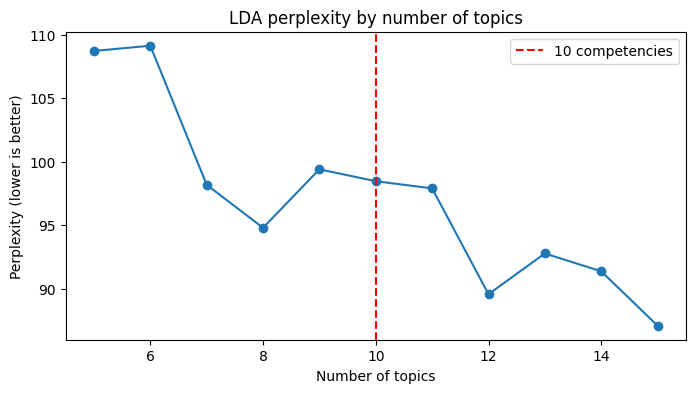

In [28]:
# Step 2.8.2: Compare topic counts using perplexity (reads X_counts from 2.8.1)

from sklearn.decomposition import LatentDirichletAllocation
import matplotlib.pyplot as plt

topic_range = list(range(5, 16))
perplexities = []

for k in topic_range:
    lda_k = LatentDirichletAllocation(n_components=k, random_state=42, learning_method="batch")
    lda_k.fit(X_counts)
    perplexities.append(lda_k.perplexity(X_counts))

print("Step 2.8.2 executed — perplexity computed for each topic count")
for k, p in zip(topic_range, perplexities):
    print(f"n_topics={k}: perplexity={p:.1f}")

plt.figure(figsize=(8, 4))
plt.plot(topic_range, perplexities, marker="o")
plt.axvline(10, color="red", linestyle="--", label="10 competencies")
plt.xlabel("Number of topics")
plt.ylabel("Perplexity (lower is better)")
plt.title("LDA perplexity by number of topics")
plt.legend()
plt.show()

### __Step 2.8.2 Notes/Insights__

- Perplexity drifts down from 108.7 (5 topics) to 87.1 (15 topics), with bumps along the way (e.g. 8→9, 12→13).
- There is no clear elbow. The curve never flattens at one value.
- Perplexity is measured on training data, so more topics will almost always look better. It is a weak guide here.
- The curve gives no data-based reason to prefer 10. At 10, perplexity is 98.5, about the same as 7 and 11.
- Decision: do not fix k from the project design. Test it with coherence in Step 2.8.2b.

Step 2.8.2b executed — coherence computed for each topic count
n_topics=5: coherence=0.609
n_topics=6: coherence=0.533
n_topics=7: coherence=0.677
n_topics=8: coherence=0.608
n_topics=9: coherence=0.697
n_topics=10: coherence=0.722
n_topics=11: coherence=0.669
n_topics=12: coherence=0.609
n_topics=13: coherence=0.729
n_topics=14: coherence=0.729
n_topics=15: coherence=0.748


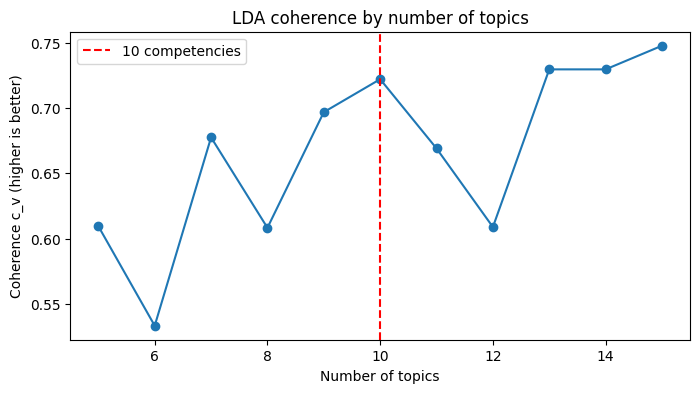

In [29]:
# Step 2.8.2b: Coherence score for each topic count (reads X_counts from 2.8.1)

import sys, subprocess
try:
    from gensim.corpora import Dictionary
    from gensim.models import CoherenceModel
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gensim"], check=True)
    from gensim.corpora import Dictionary
    from gensim.models import CoherenceModel

words = count_vectorizer.get_feature_names_out()

# --- Step 1: tokenize the course text the same way the vectorizer did ---
analyzer = count_vectorizer.build_analyzer()
vocab = set(words)
texts = [[w for w in analyzer(t) if w in vocab] for t in lda_courses["course_text_feature"]]
dictionary = Dictionary(texts)

# --- Step 2: fit LDA for each k, score topic coherence (c_v) ---
coherences = []
for k in topic_range:
    lda_k = LatentDirichletAllocation(n_components=k, random_state=42, learning_method="batch")
    lda_k.fit(X_counts)
    topics = [[words[i] for i in comp.argsort()[::-1][:10]] for comp in lda_k.components_]
    cm = CoherenceModel(topics=topics, texts=texts, dictionary=dictionary, coherence="c_v", processes=1)
    coherences.append(cm.get_coherence())

print("Step 2.8.2b executed — coherence computed for each topic count")
for k, c in zip(topic_range, coherences):
    print(f"n_topics={k}: coherence={c:.3f}")

plt.figure(figsize=(8, 4))
plt.plot(topic_range, coherences, marker="o")
plt.axvline(10, color="red", linestyle="--", label="10 competencies")
plt.xlabel("Number of topics")
plt.ylabel("Coherence c_v (higher is better)")
plt.title("LDA coherence by number of topics")
plt.legend()
plt.show()

### __Step 2.8.2b Notes/Insights__
- Coherence ranges from 0.533 (6 topics) to 0.748 (15 topics).
- It is noisy, not smooth. It dips at 8, 11 and 12, then climbs again.
- 10 topics scores 0.722, a clear local peak. It beats both 9 (0.697) and 11 (0.669).
- 15 topics scores highest (0.748), but only 0.026 above k=10. At 13 and 14 the score is 0.729.
- With 130 courses, 13 to 15 topics means about 9 courses per topic. Some topics are likely to split one competency in two.
- Coherence alone cannot separate 10 from 13 to 15 here. The gain after 10 is small.
- Decision: use k=10 as the working choice. This time the data supports it, and it also matches the 10 competencies.
- Limitation: coherence is noisy on small data, so 13 to 15 are not ruled out. We check interpretability next.

### __Step 2.8.3: Fit LDA with 10 topics and read the topics__
- We fit LDA with 10 topics, random_state=42.
- For each topic we print the top 8 words.
- We read them to see if each topic looks like a competency.
- If a topic looks mixed or split, that is evidence for trying 13 to 15 later.

In [30]:
# Step 2.8.3: Fit LDA (10 topics), show top words per topic (reads X_counts from 2.8.1)

lda = LatentDirichletAllocation(n_components=10, random_state=42, learning_method="batch")
doc_topic = lda.fit_transform(X_counts)

words = count_vectorizer.get_feature_names_out()

print("Step 2.8.3 executed — LDA fitted with 10 topics on labeled courses")
print(f"doc_topic shape: {doc_topic.shape}")
print()
for t, topic_weights in enumerate(lda.components_):
    top_idx = topic_weights.argsort()[::-1][:8]
    print(f"Topic {t}: {', '.join(words[i] for i in top_idx)}")

Step 2.8.3 executed — LDA fitted with 10 topics on labeled courses
doc_topic shape: (130, 10)

Topic 0: projects, real, practical, learners, drawn, course, examples, helps
Topic 1: day, need, designed, role, learners, client, practice, taxonomy
Topic 2: learning, driven, analytics, data, time, rate, scores, assessment
Topic 3: tool, genai, design, real, fluency, instructional, projects, content
Topic 4: short, exercises, lessons, covers, takes, applied, content, nlp
Topic 5: design, competency, content, based, fundamentals, short, exercises, lessons
Topic 6: nlp, subject, validate, publishing, matches, matter, tags, judgment
Topic 7: content, instructional, architects, module, designers, focused, built, working
Topic 8: design, adaptive, understand, personalization, path, learning, principles, taxonomy
Topic 9: content, ai, augmented, design, tools, genai, introduction, drafting


### __What the 10 topics show__

Clear topics (5 of 10):
- Topic 2 is learning analytics (COMP02), 3 is GenAI tool fluency (COMP07), 6 is NLP validation (COMP03), 8 is adaptive personalization (COMP04), and 9 is AI-augmented content design (COMP01).
- Template-filler topics: Topics 0, 4 and 5 are mostly words like "practical, examples, helps, short, exercises, lessons, covers, takes".
- Mixed topics: Topics 1 and 7 blend words from several competencies (client, taxonomy, architects, designers).
- Missing subjects: QA, ADDIE and objectives, and system architecture have no topic of their own.

### __Why this happens__

- The course generator reuses the same phrasing across all competencies, for example "short lessons" or "real projects".
- LDA groups words that appear together, so it picked up the phrasing style instead of the subject.
- A high coherence score only means the words co-occur often. It does not mean they are meaningful. That is why we planned the interpretability check.

### __How real teams handle it__

- They remove domain-specific stop words, meaning words that appear everywhere and carry no subject.
- They pick those words from the data, for example by how widely a word spreads across categories.

### __Step 2.8.3b: Find the filler words from data__

- We count how many courses contain each word.
- We count how many of the 10 competencies each word appears in.
- Words that appear in 8 or more competencies carry no subject signal.

In [31]:
# Step 2.8.3b: Find template filler words from data (reads X_counts, count_vectorizer, lda_courses)

import numpy as np

presence = (X_counts > 0).toarray()
labels = lda_courses["target_competency_id"].values

doc_freq = presence.sum(axis=0)
n_competencies = np.array([len(set(labels[presence[:, j]])) for j in range(presence.shape[1])])

vocab_df = pd.DataFrame({
    "word": count_vectorizer.get_feature_names_out(),
    "doc_freq": doc_freq,
    "n_competencies": n_competencies
}).sort_values("doc_freq", ascending=False)

print("Step 2.8.3b executed — word spread across competencies computed from courses.csv (labeled rows)")
print(f"Words appearing in 8 or more competencies: {(vocab_df['n_competencies'] >= 8).sum()} of {len(vocab_df)}")
print()
print(vocab_df.head(30).to_string(index=False))

Step 2.8.3b executed — word spread across competencies computed from courses.csv (labeled rows)
Words appearing in 8 or more competencies: 33 of 191

         word  doc_freq  n_competencies
       design        64               6
     learners        63              10
      content        59               7
         real        48              10
     projects        46              10
     learning        44               6
instructional        42               9
   understand        38               8
      lessons        35              10
    exercises        35              10
      applied        35              10
       covers        35              10
    practical        35              10
        takes        35              10
        short        35              10
        helps        34              10
       course        34              10
        drawn        34              10
     examples        34              10
           ai        33               3
      focu

### __Step 2.8.3b Notes/Insights__

- 33 of 191 words appear in 8 or more competencies.
- Most of the top words (learners, real, projects, lessons, exercises, practical, takes, short, helps) appear in all 10 competencies. They are template filler.
- Words like "instructional", "architects" and "designers" appear in 9. Could be audience phrasing, not subject.
- Subject words spread less. "ai" appears in 3 competencies, and "design" and "learning" in 6. We keep them.
- Cutoff: 8 or more competencies. The numbers show a clear gap between filler (8 to 10) and subject words (3 to 7).

### __Limitation to note__

- We used the competency labels to find the filler words.
- That makes this step less purely unsupervised.
- Without labels, real teams use document frequency, or TF-IDF weights, to spot filler.
 - Here document frequency alone cannot separate them. Some real content words appear in more courses than the filler words do.
- Filler words appear in about 25% of courses, but "content" appears in 45%.

### __Step 2.8.3c: Remove filler words, then re-check k__

- The k choice was made while the filler was still in the data.
- So we refit the word counts without these words.
- We re-run coherence for k = 5 to 15.
- We pick k again from the new numbers.

Step 2.8.3c executed — filler words removed, coherence recomputed from courses.csv (labeled rows)
Filler words removed: 33
X_counts_clean shape: (130, 158)
n_topics=5: coherence=0.318
n_topics=6: coherence=0.404
n_topics=7: coherence=0.459
n_topics=8: coherence=0.492
n_topics=9: coherence=0.582
n_topics=10: coherence=0.573
n_topics=11: coherence=0.672
n_topics=12: coherence=0.689
n_topics=13: coherence=0.628
n_topics=14: coherence=0.581
n_topics=15: coherence=0.616


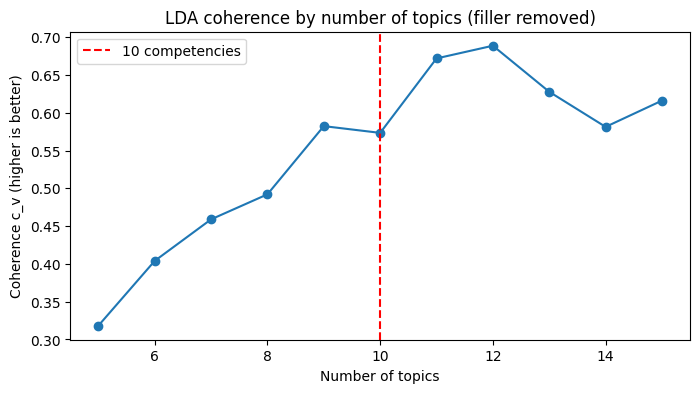

In [32]:
# Step 2.8.3c: Rebuild word counts without filler words, re-check coherence (reads courses.csv labeled rows)

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# --- Step 1: filler words found in 2.8.3b (8+ competencies) ---
filler_words = vocab_df.loc[vocab_df["n_competencies"] >= 8, "word"].tolist()
custom_stop_words = list(ENGLISH_STOP_WORDS.union(filler_words))

# --- Step 2: rebuild counts with the extended stop-word list ---
count_vectorizer_clean = CountVectorizer(stop_words=custom_stop_words, min_df=2, max_df=0.9)
X_counts_clean = count_vectorizer_clean.fit_transform(lda_courses["course_text_feature"])
words_clean = count_vectorizer_clean.get_feature_names_out()

# --- Step 3: coherence for each k on the cleaned counts ---
analyzer = count_vectorizer_clean.build_analyzer()
vocab_clean = set(words_clean)
texts_clean = [[w for w in analyzer(t) if w in vocab_clean] for t in lda_courses["course_text_feature"]]
dictionary_clean = Dictionary(texts_clean)

coherences_clean = []
for k in topic_range:
    lda_k = LatentDirichletAllocation(n_components=k, random_state=42, learning_method="batch")
    lda_k.fit(X_counts_clean)
    topics = [[words_clean[i] for i in comp.argsort()[::-1][:10]] for comp in lda_k.components_]
    cm = CoherenceModel(topics=topics, texts=texts_clean, dictionary=dictionary_clean, coherence="c_v", processes=1)
    coherences_clean.append(cm.get_coherence())

print("Step 2.8.3c executed — filler words removed, coherence recomputed from courses.csv (labeled rows)")
print(f"Filler words removed: {len(filler_words)}")
print(f"X_counts_clean shape: {X_counts_clean.shape}")
for k, c in zip(topic_range, coherences_clean):
    print(f"n_topics={k}: coherence={c:.3f}")

plt.figure(figsize=(8, 4))
plt.plot(topic_range, coherences_clean, marker="o")
plt.axvline(10, color="red", linestyle="--", label="10 competencies")
plt.xlabel("Number of topics")
plt.ylabel("Coherence c_v (higher is better)")
plt.title("LDA coherence by number of topics (filler removed)")
plt.legend()
plt.show()

### __Step 2.8.3c Notes/Insights__

- 33 filler words removed. Vocabulary dropped from 191 to 158.
- Coherence scores fell overall (peak 0.689 vs 0.748 before). The earlier scores were inflated by filler words that co-occur everywhere, so the drop is expected and the new numbers are more honest.
- Coherence now rises clearly from 5 topics (0.318) to a peak at 12 (0.689), then falls (13 to 15).
- 11 and 12 are the top two (0.672, 0.689). 10 scores 0.573, which is now clearly below them.
- So the data no longer supports k=10. The earlier "10 is a local peak" was an effect of the filler.
- Decision: use k=12 as the working choice. Limitation: 12 is not 10, so some competencies may split into two topics. We check this by reading the top words next.
- Note: the k=10 choice before was made while filler was in the data. That is why we re-checked.

### __Step 2.8.3d: Fit LDA with 12 topics and read the topics__

- We fit LDA with 12 topics on the cleaned counts.
- We print the top 8 words per topic.
- We check if topics now look like subjects (QA, ADDIE, analytics) and not template phrasing.

In [33]:
# Step 2.8.3d: Fit LDA (12 topics) on cleaned counts, show top words (reads X_counts_clean from 2.8.3c)

lda = LatentDirichletAllocation(n_components=12, random_state=42, learning_method="batch")
doc_topic = lda.fit_transform(X_counts_clean)

print("Step 2.8.3d executed — LDA fitted with 12 topics on cleaned courses.csv (labeled rows)")
print(f"doc_topic shape: {doc_topic.shape}")
print()
for t, topic_weights in enumerate(lda.components_):
    top_idx = topic_weights.argsort()[::-1][:8]
    print(f"Topic {t}: {', '.join(words_clean[i] for i in top_idx)}")

Step 2.8.3d executed — LDA fitted with 12 topics on cleaned courses.csv (labeled rows)
doc_topic shape: (130, 12)

Topic 0: client, stakeholder, consulting, compliance, business, needs, context, fundamentals
Topic 1: client, content, nlp, proactively, manage, accuracy, expectations, generated
Topic 2: design, competency, fundamentals, adaptive, taxonomy, path, personalization, principles
Topic 3: learning, data, driven, analytics, time, scores, key, metrics
Topic 4: nlp, based, curation, keyword, content, concepts, extraction, matching
Topic 5: design, content, ai, learner, augmented, review, refine, iteratively
Topic 6: content, genai, tool, tools, augmented, ai, design, releases
Topic 7: learning, data, analytics, just, decisions, intuition, justify, use
Topic 8: client, learning, solution, structured, vague, translate, asks, brief
Topic 9: content, ai, qa, generated, silently, fails, pass, letting
Topic 10: genai, tool, content, fluency, end, know, tools, operate
Topic 11: design, t

### __Step 2.8.3d Notes/Insights__

The topics now read as subjects. Template phrasing is gone.

**Possible matches:**
  - Topic 3 and 7: learning analytics (COMP02).
  - Topic 4: NLP curation and keyword matching (COMP03).
  - Topic 2: adaptive personalization and taxonomy (COMP04, partly COMP09).
  - Topic 5: AI-augmented content drafting (COMP01).
  - Topic 6 and 10: GenAI tools (COMP07).
  - Topic 9: QA of AI content (COMP10).
  - Topic 0, 1, 8: client needs, expectations, solution briefs (COMP06).
  - Topic 11: architecture, systems, reusability (COMP08).

**Note:** these are possible matches. we will check in the next step.

**Splits:**
- COMP02, COMP07 and COMP06 each span two or three topics. - This is expected with k=12 vs 10 competencies.

**Still missing:**
- ADDIE, learning objectives (COMP05). (2.8.4 downstream shows COMP05 is merged into topic 2)
- Taxonomy and KSB decomposition (COMP09) are only partly visible in topics 2 and 11.

**Likely cause:**
- those competencies share vocabulary with others in the generator's templates.
- Visual check helps more than words here, so the next step compares topics to real labels.

### __Step 2.8.4: Compare topics to competencies__

Step 2.8.4 is what tests the mapping guesses we made in the previous step. It counts, for example, how many COMP02 courses actually land in topics 3 and 7.

- For each course, take its strongest topic.
- Count how many courses of each competency land in each topic.
- A clean diagonal-like pattern means topics match competencies.
- This is exploratory only (ADR-0023). Nothing is saved to course_ksb_mapping.

Step 2.8.4 executed — dominant topic vs target_competency_id (courses.csv, labeled rows)
dominant_topic        0   1   2   3   4   5   6   7   8   9   10  11
target_competency_id                                                
COMP01                 0   0   0   0   0   4   9   0   0   0   0   0
COMP02                 0   0   0  10   0   0   0   5   0   0   0   0
COMP03                 0   4   0   0   5   0   0   0   0   3   0   0
COMP04                 0   0  10   0   0   3   0   0   0   0   0   0
COMP05                 0   0  13   0   0   0   0   0   0   0   0   0
COMP06                 5   5   0   0   0   0   0   0   4   0   0   0
COMP07                 0   0   0   0   0   0   5   0   0   0   6   0
COMP08                 0   0   0   3   0   0   0   4   0   0   0   5
COMP09                 0   0   8   0   0   0   0   0   0   0   0   4
COMP10                 0   0   0   0   0   0   0   0   0  15   0   0

Share of each competency's courses in its top topic:
target_competency_id
COMP01  

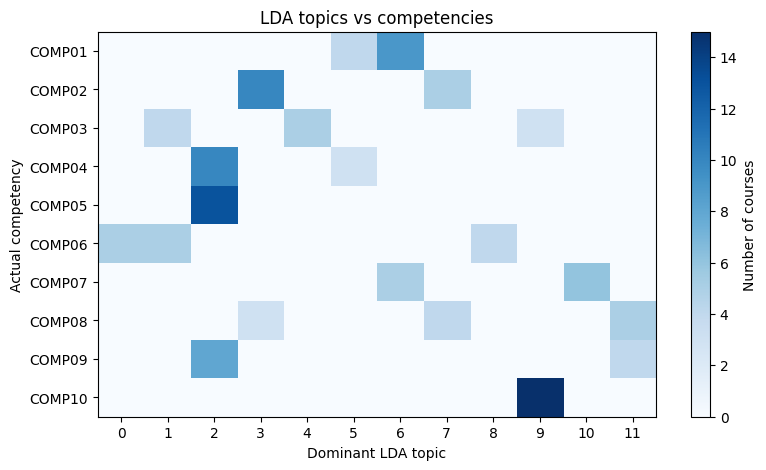

In [34]:
# Step 2.8.4: Cross-tab of dominant topic vs actual competency (reads doc_topic from 2.8.3d, lda_courses)

lda_courses = lda_courses.copy()
lda_courses["dominant_topic"] = doc_topic.argmax(axis=1)

crosstab = pd.crosstab(lda_courses["target_competency_id"], lda_courses["dominant_topic"])

print("Step 2.8.4 executed — dominant topic vs target_competency_id (courses.csv, labeled rows)")
print(crosstab)

# share of each competency's courses that land in its single most common topic
purity = (crosstab.max(axis=1) / crosstab.sum(axis=1)).round(2)
print()
print("Share of each competency's courses in its top topic:")
print(purity)

plt.figure(figsize=(9, 5))
plt.imshow(crosstab.values, cmap="Blues", aspect="auto")
plt.xticks(range(crosstab.shape[1]), crosstab.columns)
plt.yticks(range(crosstab.shape[0]), crosstab.index)
plt.colorbar(label="Number of courses")
plt.xlabel("Dominant LDA topic")
plt.ylabel("Actual competency")
plt.title("LDA topics vs competencies")
plt.show()

### __Step 2.8.4 Notes/Insights__

- Clean topics: COMP10 (15/15 in topic 9) and COMP05 (13/13 in topic 2) are fully captured.
- Mostly clean: COMP04 (77%), COMP01 (69%), COMP02 (67%), COMP09 (67%) have one dominant topic.
- Spread out: COMP06 (36%), COMP03 (42%), COMP08 (42%), COMP07 (55%) split across 2 or 3 topics.
- Topic 2 is shared by COMP04, COMP05 and COMP09 (31 courses). LDA cannot separate them.

### __About our guess in 2.8.3d:__
- COMP05 (ADDIE, objectives) has no topic of its own.
- It sits inside topic 2, so the earlier note about it being "missing" is partially true: LDA merged it with others.
- Three guesses are wrong/ incomplete: topic 5 also holds COMP04 courses, topic 7 holds COMP08 courses (not only COMP02), and topic 3 holds some COMP08 courses.

**Overall: LDA roughly recovers the competency structure without seeing labels, but not cleanly.**

Limitation
- k=12 vs 10 competencies, plus shared template vocabulary, makes one-to-one mapping impossible.
- LDA is exploratory here (ADR-0023).
- The supervised classifier and TF-IDF remain far better at assigning competencies.

### __Step 2.8.5: Close out LDA (save artifact)__

- Save the topic top-words table and the cross-tab as CSV artifacts, not to course_ksb_mapping.
- Save to outputs/, per ADR-0023.

In [35]:
# Step 2.8.5: Save LDA artifacts (reads lda, words_clean from 2.8.3d, crosstab from 2.8.4)

OUTPUT_DIR = '/content/drive/MyDrive/Portfolio/LuminaLearningGroup/outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)

topic_words = pd.DataFrame({
    "topic": range(12),
    "top_words": [", ".join(words_clean[i] for i in comp.argsort()[::-1][:10]) for comp in lda.components_]
})
topic_words.to_csv(os.path.join(OUTPUT_DIR, "lda_topic_words.csv"), index=False)
crosstab.to_csv(os.path.join(OUTPUT_DIR, "lda_topic_vs_competency.csv"))

print("Step 2.8.5 executed — LDA artifacts saved to outputs/")
print("lda_topic_words.csv, lda_topic_vs_competency.csv")

Step 2.8.5 executed — LDA artifacts saved to outputs/
lda_topic_words.csv, lda_topic_vs_competency.csv


### __Step 2.9: Summary and close-out__
- 2.9 has three parts: check what is saved, write the NB02 summary, and log the decisions.
- We do them one at a time, starting with a check of what is on disk.



### __Step 2.9.1: Verify the NB02 outputs__
- We reload every file NB02 saved.
- We print row counts and key columns.
- We check them against the numbers reported earlier in this notebook.
- This makes the notebook's summary traceable to real files.


In [36]:
# Step 2.9.1: Verify NB02 outputs on disk (reads data/processed, data/raw, outputs)

checks = {
    "data/processed/employee_ksb_gaps.csv": os.path.join(PROCESSED_DIR, "employee_ksb_gaps.csv"),
    "data/processed/course_ksb_mapping.csv": os.path.join(PROCESSED_DIR, "course_ksb_mapping.csv"),
    "data/raw/courses.csv": os.path.join(RAW_DIR, "courses.csv"),
    "outputs/lda_topic_words.csv": os.path.join(OUTPUT_DIR, "lda_topic_words.csv"),
    "outputs/lda_topic_vs_competency.csv": os.path.join(OUTPUT_DIR, "lda_topic_vs_competency.csv"),
}

print("Step 2.9.1 executed — NB02 output files checked")
for name, path in checks.items():
    df = pd.read_csv(path)
    print(f"{name}: {len(df)} rows, {len(df.columns)} columns")

final_map = pd.read_csv(checks["data/processed/course_ksb_mapping.csv"])
final_courses = pd.read_csv(checks["data/raw/courses.csv"])

print()
print("course_ksb_mapping: match_method counts")
print(final_map["match_method"].value_counts())
print()
print("course_ksb_mapping: curation_status counts")
print(final_map["curation_status"].value_counts())
print()
print("courses.csv: columns added or populated in NB02")
for col in ["ksb_layer", "likely_duplicate_of", "duplicate_cluster_id", "course_text_feature"]:
    print(f"{col}: {final_courses[col].notna().sum()} non-null of {len(final_courses)}")

Step 2.9.1 executed — NB02 output files checked
data/processed/employee_ksb_gaps.csv: 1650 rows, 6 columns
data/processed/course_ksb_mapping.csv: 9240 rows, 9 columns
data/raw/courses.csv: 154 rows, 16 columns
outputs/lda_topic_words.csv: 12 rows, 2 columns
outputs/lda_topic_vs_competency.csv: 10 rows, 13 columns

course_ksb_mapping: match_method counts
match_method
tfidf        4620
embedding    4620
Name: count, dtype: int64

course_ksb_mapping: curation_status counts
curation_status
algo_suggested    9210
ld_reviewed         19
ld_approved         11
Name: count, dtype: int64

courses.csv: columns added or populated in NB02
ksb_layer: 154 non-null of 154
likely_duplicate_of: 27 non-null of 154
duplicate_cluster_id: 27 non-null of 154
course_text_feature: 154 non-null of 154


### __Step 2.9.2: NB02 summary__


**What NB02 built:**
- Employee KSB gaps for the 55 focus-role employees (1,650 rows).
- Knowledge or skill tags for all 154 courses.
- TF-IDF and embedding matches for every course-KSB pair (9,240 rows). TF-IDF stays production.
- 12 duplicate clusters covering 27 courses.
- A rule-based review queue: 11 matches approved, 19 sent for review.

**What the comparisons showed:**
- TF-IDF and embeddings agree on 17 of 30 top matches.
- The classifier and TF-IDF both scored 100%, so the benchmark could not separate them on synthetic data.
- LDA needed filler-word removal before its topics made sense. Even then, three competencies shared one topic.
- Both methods picked the right course for all 30 KSBs (2.7.6). A disagreement means two valid candidates.

**Handed to NB03:**
- employee_ksb_gaps.csv and course_ksb_mapping.csv.
- Only ld_approved and ld_modified matches can become recommendations.

**Left for NB03 to decide:**
- A rule for the 19 ld_reviewed matches.
- The role of ksb_layer.
- Whether duplicate clusters should limit recommendations.

### __Step 2.9.3: Decisions logged__

NB02 added five decisions to `decisions.md` (ADR-0038 to ADR-0042).

- **ADR-0038:** course labels (`target_ksb_id`, `target_competency_id`) saved in `courses.csv`. 24 courses have none: 20 orphans and 4 arXiv rows.
- **ADR-0039:** classifier and TF-IDF both scored 39/39. The benchmark cannot separate them on synthetic data.
- **ADR-0040:** LDA topic count (k=12) chosen by coherence, after removing 33 filler words.
- **ADR-0041:** duplicates found at a 0.95 similarity threshold. 12 clusters, 27 courses. Detection only.
- **ADR-0042:** rule-based curation. 11 matches approved, 19 sent for review.

**Schema changes:**
- `courses`: added `target_ksb_id`, `target_competency_id`, `duplicate_cluster_id`.
- `course_ksb_mapping`: `is_production`, `is_recommended` and `curation_status` are now populated.
- `course_text_feature` is a helper column, not part of the schema.

### __Where we go next: NB03__

NB03 turns approved matches and employee gaps into learning paths.

**Files NB03 reads:**
- `data/processed/employee_ksb_gaps.csv`
- `data/processed/course_ksb_mapping.csv`
- `data/raw/courses.csv`

**Open decisions for NB03:**
- How do the 19 `ld_reviewed` matches become approved, modified or rejected?
- What is `ksb_layer` used for?
- Should duplicate clusters limit what gets recommended?

**Reminder:** only gaps with `gap_size > 0` need a course. Negative gaps mean the employee is above the requirement.

## __End of NB02__